# Cellohood Data Preparation & Training Tutorial

In this notebook we will go through an example training / post-processing of Cellohood model.


## Data Preparation

At the base of the Cellohood analysis is the single cell marker expression matrix with cell positions. In order to proceed one needs to fill out the following variables:

- `DATA_PATH` - path to a cell data,
- `MARKER_COL_NAMES` - a collection of marker columns,
- `DISTANCE_THRESHOLD` - cells will be clustered into bags of roughly this diamater. This distance should reflect the distance at which you expect the cell interactions to be valid,
- `POSITION_COLS` - a list / tuple with columns of cell positions. Cellohood accepts any dimensionality of the input,
- `IMAGE_COL_NAME` - a column with information about from which image / slide comes from,
- `SAMPLE_COL_NAME` - as some patients / mice / etc. might have multiple slides - this additional column represents to which columns does a given cell belongs.

In [1]:
import pandas
import joblib

from ccs import ccs
import cellohood


DATA_PATH = '/raid/immucan/immuw/image_analysis/analysis/UW/packages/IMMUW/scripts/test_goltsev_100_v3.csv'
data_df = pandas.read_csv(DATA_PATH)


MARKER_COL_NAMES = [
    'CD45', 
    'Ly6C', 
    'TCR', 
    'Ly6G', 
    'CD19', 
    'CD169', 
    'CD106', 
    'CD3', 
    'CD1632', 
    'CD8a', 
    'CD90', 
    'F480', 
    'CD11c', 
    'Ter119', 
    'CD11b', 
    'IgD', 
    'CD27', 
    'CD5', 
    'CD79b', 
    'CD71', 
    'CD31', 
    'CD4', 
    'IgM', 
    'B220', 
    'ERTR7', 
    'CD35', 
    'CD2135', 
    'CD44', 
    'NKp46', 
    'MHCII', 

]


DISTANCE_THRESHOLD = 100.
POS_COL_NAMES = ['tile.X', 'tile.Y']
IMAGE_ID_COLUMN = 'sample'
SAMPLE_COL_NAME = 'sample'

TRAIN_MODEL = False
SAVING_PATH = f'SPLEEN_{DISTANCE_THRESHOLD}'

TRAIN_LATENT_DIRECTIONS = False
LD_SAVING_PATH = 'spleen_ld_se.pickle'

LOAD_CELLO_BAG_DF = False
FULL_CELLO_BAG_DF_PATH = 'SpleenBCDf'
APPLY_ARCSINH_TRANSFORM = False

TRANSFORM_TO_CELLO_BAG = True
CELLO_BAG_PATH = 'spleen_cello_bag.pickle'

FINAL_DF_SAVING_PATH = 'final_spleen.csv'

/tmp/ipykernel_2946542/3548171592.py:9: DtypeWarning: Columns (48,49) have mixed types. Specify dtype option on import or set low_memory=False.
  data_df = pandas.read_csv(DATA_PATH)


First step in the data preprocessing is to transform a cell df to a `BagCelloDf` object. This methods runs the hierarchical clustering cells into bags using `DISTANCE_THRESHOLD` as a threshold. It later assigns each cell its bag id (by default `cellohood_neighborhood_cluster`). The object contains:
- `cell_df` - a transformed cell data frame with bag assignment,
- `image_id_column`- check the description of `IMAGE_ID_COLUMN` above,
- `pos_col_names` - check the description of `POS_COL_NAMES` above,
- `distance_threshold` - check the description of `DISTANCE_THRESHOLD` above,
- `marker_col_names` - check the `MARKER_COL_NAMES` above,
- `cellohood_neighborhood_cluster_colname` - in this column an id of a cell's bag is stored (by default `cellohood_neighborhood_cluster`.
        

In [2]:
if not LOAD_CELLO_BAG_DF:
    print('ok')
    bag_cello_df = cellohood.transform_df_to_bag_cello_df(
        df_=data_df,
        image_id_column=IMAGE_ID_COLUMN,
        pos_col_names=POS_COL_NAMES,
        distance_threshold=DISTANCE_THRESHOLD,
        marker_col_names=MARKER_COL_NAMES,
    )
    if APPLY_ARCSINH_TRANSFORM:
        bag_cello_df = cellohood.apply_arcsinh_to_bag_cello_df(bag_cello_df)
    cellohood.save_bag_cello_df(bag_cello_df=bag_cello_df, path=FULL_CELLO_BAG_DF_PATH, exist_ok=True)
else:
    bag_cello_df = cellohood.load_bag_cello_df(path=FULL_CELLO_BAG_DF_PATH)

ok


In [3]:
0

0

(array([2.7720e+03, 1.5478e+04, 5.9569e+04, 2.4758e+04, 1.7002e+04,
        1.4449e+04, 1.7900e+03, 6.5600e+02, 2.1000e+01, 7.0000e+00]),
 array([ 1. ,  2.4,  3.8,  5.2,  6.6,  8. ,  9.4, 10.8, 12.2, 13.6, 15. ]),
 <BarContainer object of 10 artists>)

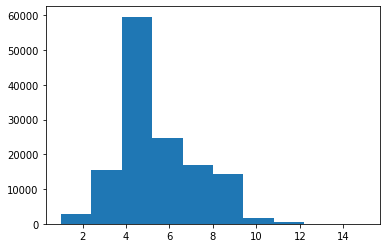

In [4]:
import matplotlib.pyplot as plt

plt.hist(bag_cello_df.cell_df.groupby('cellohood_neighborhood_cluster').size())

If one wants to apply a popular `arcsinh(x / 5.)` transform - there is a function for that:

In [5]:
#_ = cellohood.apply_arcsinh_to_bag_cello_df(bag_cello_df, inplace=True)

Now - it's time for train / test split of the `bag_cello_df`. The code below produces two `BagCelloDf`s - train and test ones. In case, when one wants to train Cellohood without test set (treating it as a sort of cellular neighborhood PCA) - the `split_percentage` should be set to `1.`. In this case, the `test_bag_cello_df` is set to `None`.

**NOTE:** this tests are splitted by samples - so that separate samples are in the train and test sets.

In [6]:
train_bag_cello_df, test_bag_cello_df = cellohood.split_bag_cello_df_by(
    bag_cello_df,
    by=SAMPLE_COL_NAME,
    split_percentage=1.,
)

It is good to standardize data first. The code below uses `standardize_bag_cello_df` function that accepts as its input:
- `train_bag_cello_df`, `test_bag_cello_df` - train and test `BagCelloDfs`,
- `marker_scaler` (default `"standard"`) - a marker scaler. For `"standard"` value it uses Standard Scaler, for `"min-max"` it uses MinMaxScaler, `None` uses Identity Scaler. One may also pass any object with `transform` method that will transform cell marker expressions,
- `pca_dimensions` (default `0`) - number of PCA dimensions used for the analysis. If it is set to `0` no PCA transformation is applied,
- `inplace` (default `False`) - if standarization should be performed in place,
- `fit_marker_scaler` - in case when one passes it's own scaler, this indicates if it will be fitted or not. If set to `True` a passed scaler object should have a `fit` method.

It fits `marker_scaler` on the `train_bag_cello_df`, and applies it to the `test_bag_cello_df` (it automatically covers if `test_bag_cello_df` is `None`). It outputs a `StandardizedBagCelloDfs` `namedtuple` containing:

- `train_cello_df`, `test_cello_df`, `BagCelloDf` objects with scaled `cell_df`s,
- `marker_scaler` - scaler instance,
- `marker_col_names` - names of marker columns,
- `output_size` - size of the single cell vectors (`pca_dimensions` if PCA was applied, `len(marker_col_names)` otherwise).

In [7]:
standardized_cello_dfs = cellohood.standardize_bag_cello_df(
    train_bag_cello_df=train_bag_cello_df, 
    test_bag_cello_df=test_bag_cello_df,
    marker_col_names=MARKER_COL_NAMES,
)

Now, it's time to train `Cellohood`. `cellohood.train` method accepts as its input:


- `standardized_cello_dfs` - a `StandardizedBagCelloDfs` object that `Cellohood` will be trained on,
- `batch_size: int = 512` - a batch size used in the training,
- `epoch_nb: int = 1000` a number of epochs,
- `optimizer_lr: float = 0.0001` - learning rate used by `ADAM` optimizer,
- `optimizer_clipnorm: float = 1.0` - a clip norm for optimizer,
- `use_cuda: bool = True` - if model should be trained on `GPU`,
- `layer_size: int = 128` - a size of the transformer layer sizes for both encoder and decoder,
- `intermediate_layer_size: int = 256` - a size of a hidden transformer later,
- `latent_size: int = 64` - size of a `Cellohood` latent,
- `tensorboard_path: Optional[str] = None` - a log path to optional TensorBoard callback.

This method outputs `CellohoodModel` `namedtuple` with the following fields:
- `model` - an instance of a `Keras` `Cellohood` model,
- `history` - `Keras` training history,
- `marker_scaler` - scaler used in training,
- `marker_col_names` - names of marker used,
- `output_size` output size of a model,
- `max_neighborhood_size` - a maximal bag size used by the model.

In [8]:
if TRAIN_MODEL:
    cello_train_result = cellohood.train(
        standardized_cello_dfs=standardized_cello_dfs,
        epoch_nb=1000,
        use_cuda=True,
        #batch_size=256,
    )

once we have a model, we can serialize its result using `cellohood.save_cello_train_result` function. Deserialization is performed by `cellohood.load_cello_train_result`:

In [9]:
import os

os.environ['CUDA_VISIBLE_DEVICES'] = '0'

if TRAIN_MODEL:
    cellohood.save_cello_train_result(cello_train_result, SAVING_PATH)
else:
    cello_train_result = cellohood.load_cello_train_result(SAVING_PATH)

{'output_size': 30, 'max_neighborhood_size': 15, 'latent_size': 64, 'layer_size': 128, 'intermediate_layer_size': 256}


2025-08-18 14:52:45.678250: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-08-18 14:52:45.683684: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-08-18 14:52:45.684174: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
/raid/immucan/immuw/cellohood_venv/lib/python3.8/site-packages/keras/engine/training_v1.py:2079: UserWarning: `Model.state_updates` will be removed in a future version. This property should not be used in TensorFlow 2.0, as `updates` are applied automatically.
  updates=self.state_updates,
2025-08-18 14:52:46.349100: I tensorflow/core/pla

Now - we are ready to obtain the model results. In order to run prediction of a `Cellohood` model on the `BagCelloDf`, one may use `cellohood.run_prediction_on_cell_df`. Note however, that the data that this model is used on should not be scaled, as the scaling of the data is performed using scaler used during the train. That's why in the code below we use non-scaled `BagCelloDf`:

In [10]:
cello_prediction = cellohood.run_prediction_on_cello_df(
    cello_train_result,
    bag_cello_df,
)

/raid/immucan/immuw/cellohood_venv/lib/python3.8/site-packages/keras/engine/training_v1.py:2079: UserWarning: `Model.state_updates` will be removed in a future version. This property should not be used in TensorFlow 2.0, as `updates` are applied automatically.
  updates=self.state_updates,


It outputs `CelloPrediction` `namedtuple` with fields:
- `cell_predictions` - with dataframe of Cellohood cell representations, together with image and position information,
- `bag_predictions` - with dataframe of Cellohood bag representations, together with image and position information,
- `cello_columns` - with set of column names storing the Cellohood representations,
- `cellohood_neighborhood_cluster_colname` - column with the cellohood bag index,
- `image_id_column` - column with information about the image id,
- `pos_col_names` - positional columns.

As we use a set of disjoint bags in the training, we decided to compensate for the effect that disjoint tissue cutting might have on results - by spatially smoothing the results. Here - the value for each cell is spatially smoothed across all cells within a `distance_threshold`. In our experiments we set it to `DISTANCE_THRESHOLD` that is the same threshold as we used in original tissue cutting. Note - that as this process might be time / memory consuming we implemented multiprocess setup which uses `cache_path` folder to cache multiprocess result. Be default, for safety reasons, we implemented the assertion that this folder does not exist, so make sure that you use unused folder.

In [11]:
import importlib
from cellohood.data_processing import spatial_directions
from cellohood.training import training

importlib.reload(cellohood)
importlib.reload(spatial_directions)
importlib.reload(training)

<module 'cellohood.training.training' from '/raid/immucan/immuw/cellohood/cellohood/training/training.py'>

In [12]:
!rm -r new_cache

rm: cannot remove 'new_cache': No such file or directory


In [13]:
smoothed_df_result = cellohood.smooth_cellohood_prediction(
    cello_prediction,
    distance_threshold=DISTANCE_THRESHOLD,
    cache_path='new_cache',
)

In [14]:
from sklearn.decomposition import PCA


decomposer = PCA()
decomposed = decomposer.fit_transform(
    smoothed_df_result.cell_predictions[smoothed_df_result.cello_columns].values,    
)

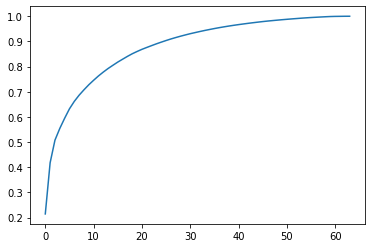

In [15]:
plt.plot(decomposer.explained_variance_ratio_.cumsum())

In [16]:
decomposer.explained_variance_ratio_.cumsum() <= 0.5

array([ True,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False])

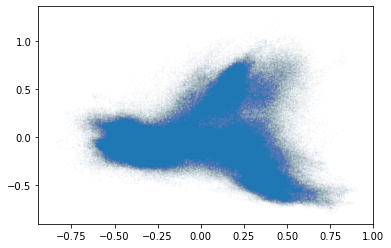

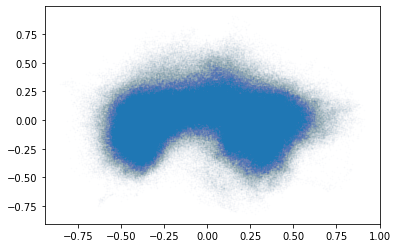

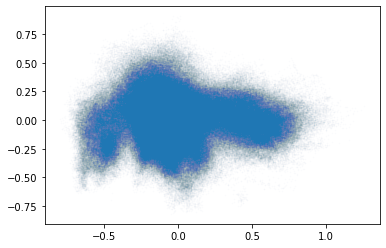

In [17]:
plt.scatter(
    decomposed[:, 0],
    decomposed[:, 1],
    #c=bag_cello_df.cell_df['layer'].apply(lambda x: layers_.index(x)),
    alpha=0.01,
    s=1,
)
plt.show()
plt.scatter(
    decomposed[:, 0],
    decomposed[:, 2],
    #c=bag_cello_df.cell_df['layer'].apply(lambda x: layers_.index(x)),
    alpha=0.01,
    s=1,
)
plt.show()
plt.scatter(
    decomposed[:, 1],
    decomposed[:, 2],
    #c=bag_cello_df.cell_df['layer'].apply(lambda x: layers_.index(x)),
    alpha=0.01,
    s=1,
)

After smoothin it's worth to delete `cache`:

In [18]:
!rm -r new_cache/

Now, let's prepare latent directions. Latent directions is a method that provides opportunity to set the resolution of the analysis of the latent space. It works in a following way:

1. For a set of `explained_variance_levels` it computes the PCA of the provided `columns` in `df`,
2. It clusters it separately using [`cellohood_cluster_selection`](https://github.com/marmarmarmar/cellohood-cluster-selection) algorithm.

A function `get_latent_direction` accepts:
- `df` - Dataframe with latent representations,
- `columns` - column names of latent representations to use,
- `explained_variance_levels` - levels of variance used for the analysis,
- `min_nb_of_clusters` - minimal number of clusters checked in the cluster selection algorithm,
- `max_nb_of_clusters` - maximal number of clusters checked in the cluster selection algorithm,
- `clusters_step` - the difference between consecutive number of clusters candidates checked in the cluster selection algorithm,
- `nb_of_tries_per_cluster_nb` - how many alternative runs are used for a given cluster number,
- `take_every_example_for_training` - a subsampling ratio for examples for cluster selection.

It returns a `LatentDirectionResult` namedtuple with the following fields:
- `explained_variance_level_to_n_components` - dictionary that stores the information about how many dimensions were elected for a given variance level,
- `explained_variance_level_to_ccs_result` - dictionary that stores `cellohood_cluster_selection` results for a given variance level,
- `pca_sm_data` - array with a `PCA` transformed data,
- `pca` - a fitted `sklearn` `PCA` transformer.

{0.5: 3, 0.75: 12, 1.0: 64}


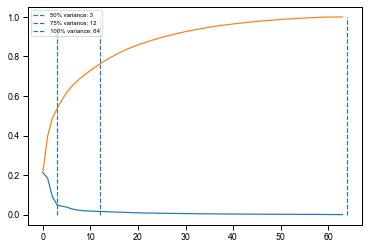

0.5


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 25/25 [10:20<00:00, 24.82s/it]


0.75


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 25/25 [10:30<00:00, 25.23s/it]


1.0


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 25/25 [11:03<00:00, 26.56s/it]


In [227]:
if TRAIN_LATENT_DIRECTIONS:
    latent_direction_result = cellohood.get_latent_directions(
        df=smoothed_df_result.bag_predictions,
        columns=smoothed_df_result.cello_columns,
        explained_variance_levels=(0.5, 0.75, 1.0),
        min_nb_of_clusters=5,
        max_nb_of_clusters=30,
        nb_of_tries_per_cluster_nb=5,
        take_every_example_for_training=100,
        clusters_step=1,
    )
    joblib.dump(latent_direction_result, LD_SAVING_PATH)
else:
    latent_direction_result = joblib.load(LD_SAVING_PATH)

In [266]:
latent_direction_result.explained_variance_level_to_n_components

{0.5: 3, 0.75: 12, 1.0: 64}

In [267]:
cellohood.summarize_latent_direction_result(latent_direction_result)

Latent Direction Summary:
Variance: 0.5 (dim=3), selected clusters = [11, 16, 24].
Variance: 0.75 (dim=12), selected clusters = [18].
Variance: 1.0 (dim=64), selected clusters = [11, 14, 18, 21, 26].


In [230]:
import ccs

In [231]:
balbc_samples_df_all = bag_cello_df.cell_df[
    bag_cello_df.cell_df['sample'].apply(lambda x: x.startswith('BALB'))
]
balbc_decomposed = decomposed[
    bag_cello_df.cell_df['sample'].apply(lambda x: x.startswith('BALB')).values
]

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [05:38<00:00, 42.29s/it]


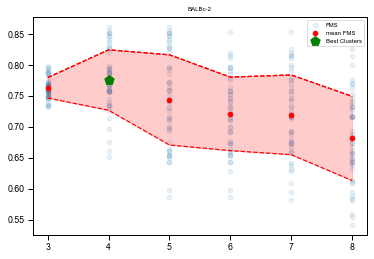

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [05:28<00:00, 41.11s/it]


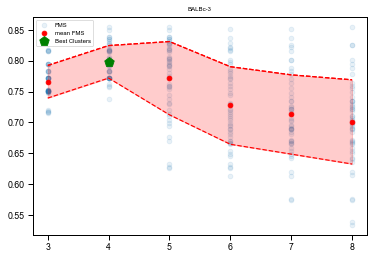

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [05:05<00:00, 38.13s/it]


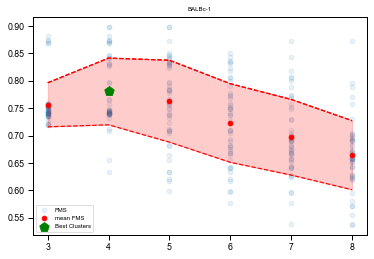

In [232]:
balbc_samples = set(balbc_samples_df_all['sample'])

sample_to_ccs_result = {}

for sample in balbc_samples:
    sample_to_ccs_result[sample] = ccs.cellohood_cluster_selection(
        x=balbc_decomposed[balbc_samples_df_all['sample'] == sample, :3],
        clusters_to_analyze=list(range(2, 10)),
        #take_every_example_for_training=10,
    )
    ccs.plot_ccs_result(sample_to_ccs_result[sample])
    plt.title(sample)
    plt.show()

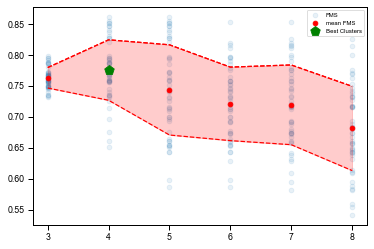

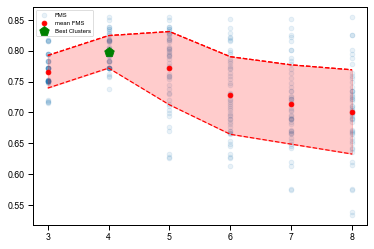

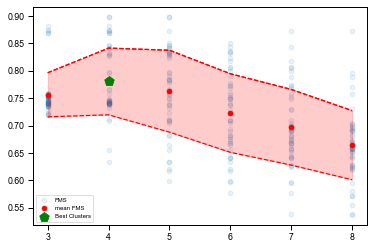

In [233]:
for sample in balbc_samples:
    ccs.plot_ccs_result(sample_to_ccs_result[sample])
    plt.show()

In [234]:
import numpy


compartments = [
    'B-zone', 'PALS', 'marginal zone', 'red pulp',  'NoAnnotation', numpy.nan
]

In [235]:
compartments

['B-zone', 'PALS', 'marginal zone', 'red pulp', 'NoAnnotation', nan]

In [236]:
balbc_samples_df_all['CompartmentValidInt'] = balbc_samples_df_all['Compartment'].apply(lambda x: compartments.index(x))

/tmp/ipykernel_2946542/3900463650.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  balbc_samples_df_all['CompartmentValidInt'] = balbc_samples_df_all['Compartment'].apply(lambda x: compartments.index(x))


In [237]:
balbc_samples_df = balbc_samples_df_all#[#balbc_samples_df_all['CompartmentValidInt']]

In [238]:
balbc_decomposed = balbc_decomposed#[balbc_samples_df_all['CompartmentValidInt']]

In [239]:
from collections import defaultdict
from matplotlib import colors as mcolors

COMPARTMENT_TO_COLOR = defaultdict(lambda: mcolors.CSS4_COLORS['white'])

COMPARTMENT_TO_COLOR['B-zone'] = mcolors.BASE_COLORS['k']
COMPARTMENT_TO_COLOR['PALS'] = mcolors.BASE_COLORS['b']
COMPARTMENT_TO_COLOR['marginal zone'] = mcolors.CSS4_COLORS['yellow']
COMPARTMENT_TO_COLOR['red pulp'] = mcolors.CSS4_COLORS['red']
COMPARTMENT_TO_COLOR['NoAnnotation'] = mcolors.CSS4_COLORS['white']
COMPARTMENT_TO_COLOR[numpy.nan] = mcolors.CSS4_COLORS['white']

In [240]:
from matplotlib.colors import LinearSegmentedColormap


colors_cc = LinearSegmentedColormap.from_list('clusters', list(COMPARTMENT_TO_COLOR.values()), N=6)

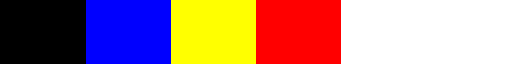

In [241]:
colors_cc

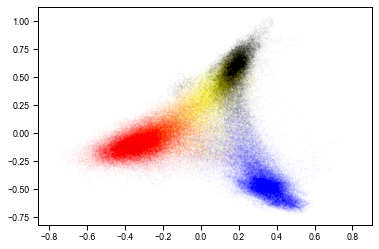

In [242]:
plt.scatter(
    balbc_decomposed[:, 0],
    balbc_decomposed[:, 1],
    c=balbc_samples_df['Compartment'].apply(lambda x: compartments.index(x)),
    alpha=0.01,
    s=1,
    cmap=colors_cc,
)

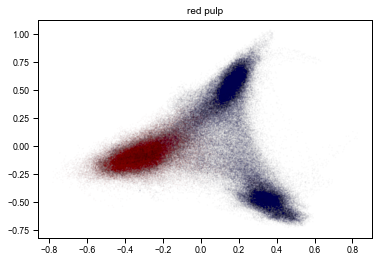

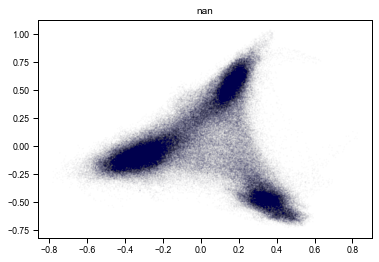

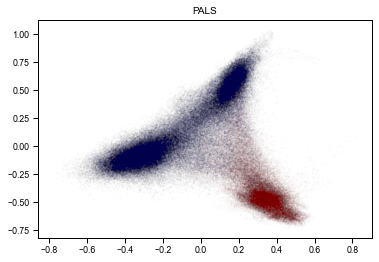

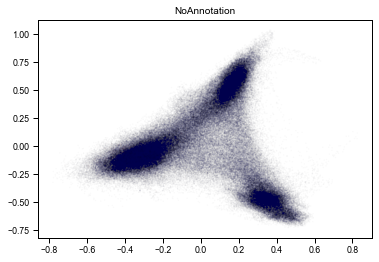

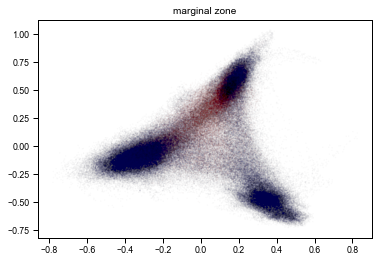

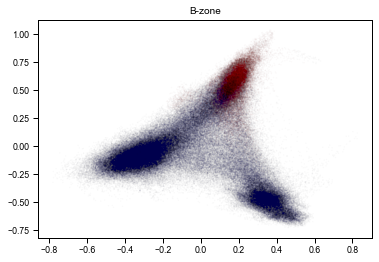

In [243]:
for comp_ in balbc_samples_df['Compartment'].unique():
    plt.scatter(
        balbc_decomposed[:, 0],
        balbc_decomposed[:, 1],
        c=balbc_samples_df['Compartment'] == comp_,
        alpha=0.01,
        s=1,
        cmap='seismic',
    )
    plt.title(comp_, size=10)
    plt.show()

/tmp/ipykernel_2946542/285791921.py:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(


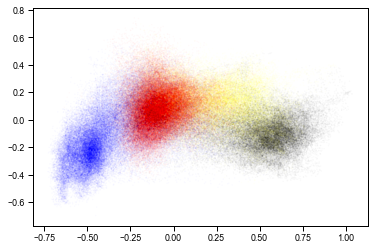

In [244]:
plt.scatter(
    balbc_decomposed[:, 1],
    balbc_decomposed[:, 2],
    c=balbc_samples_df['Compartment'].apply(lambda x: COMPARTMENT_TO_COLOR[x]),
    alpha=0.01,
    s=1,
    cmap=colors_cc,
)

/tmp/ipykernel_2946542/1787079977.py:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(


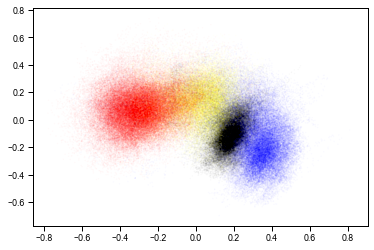

In [245]:
plt.scatter(
    balbc_decomposed[:, 0],
    balbc_decomposed[:, 2],
    c=balbc_samples_df['Compartment'].apply(lambda x: COMPARTMENT_TO_COLOR[x]),
    alpha=0.01,
    s=1,
    cmap=colors_cc,
)

In [246]:
NB_OF_CLUSTERS = 4
RANDOM_STATE = 42

In [247]:
from sklearn.metrics import adjusted_mutual_info_score as ami
from sklearn.metrics import f1_score 
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

In [248]:
spleen_train_data = balbc_decomposed[:, :3]
spleen_full_train_data = balbc_decomposed[:, :3]

In [249]:
from collections import Counter


Counter(balbc_samples_df['CompartmentValidInt'])

Counter({3: 86517, 5: 9377, 1: 65809, 4: 1047, 2: 51663, 0: 40246})

BALBc-2


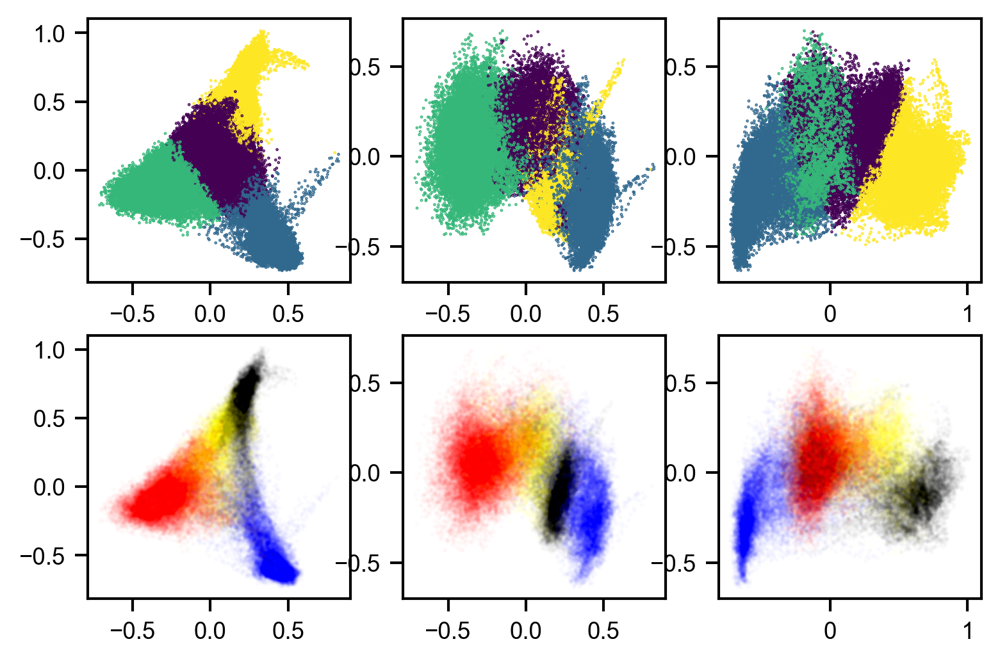

BALBc-3


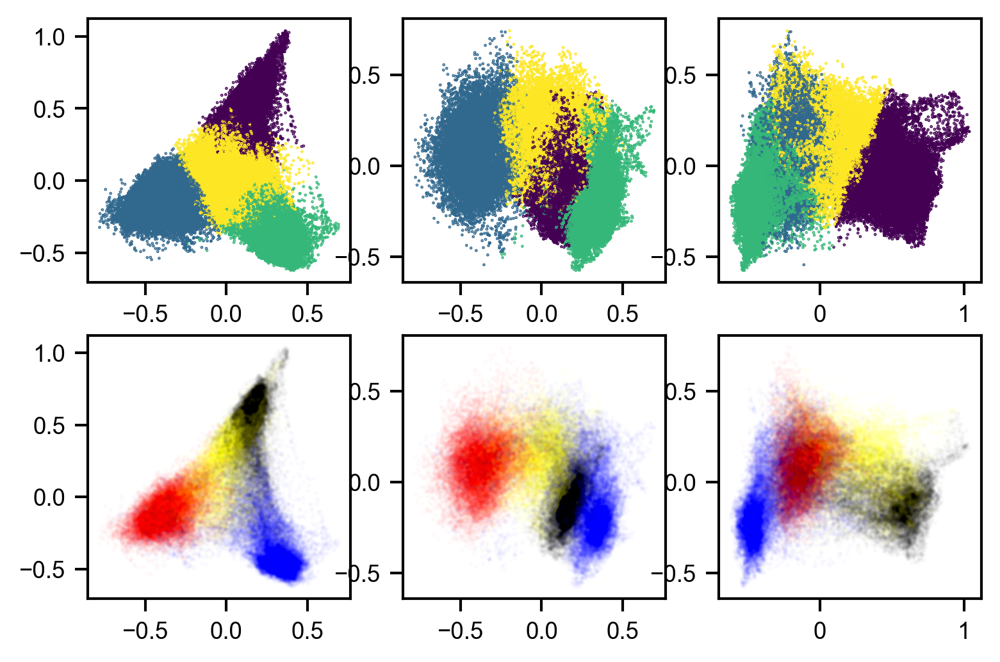

BALBc-1


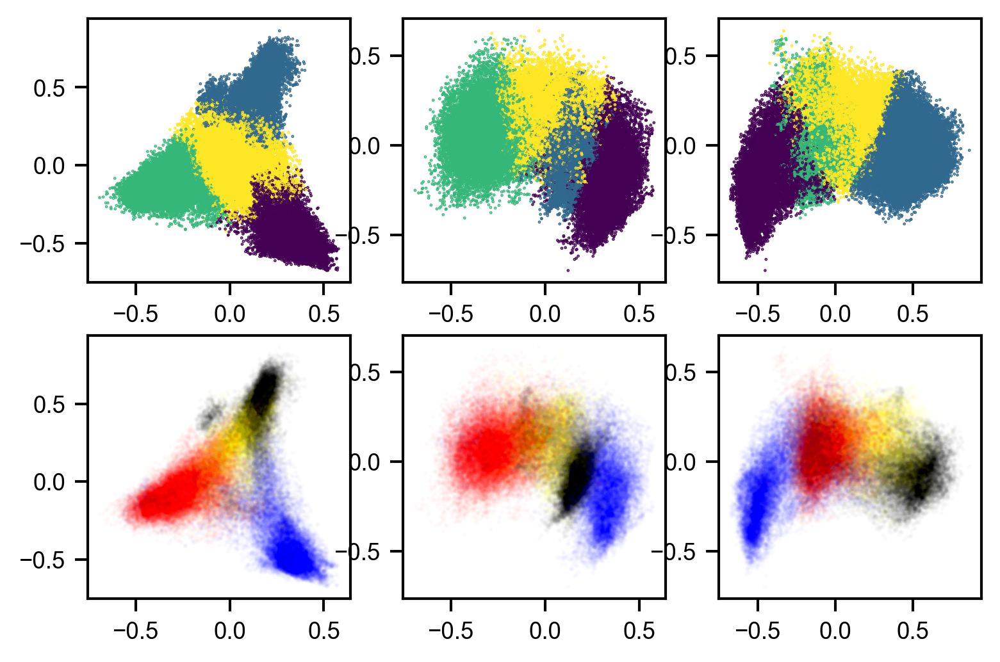

In [250]:
from sklearn.metrics import adjusted_rand_score

sample_amis, sample_f1s, sample_aris = [], [], []

sample_to_predictions = {}


for sample in set(balbc_samples_df['sample']):
    print(sample)
    sample_df = balbc_samples_df[balbc_samples_df['sample'] == sample]
    sample_decomposed = balbc_decomposed[balbc_samples_df['sample'] == sample]
    gm = sample_to_ccs_result[sample].best_clusterers[4]
    classes = gm.predict(sample_decomposed[:, :3])

    classes_dict = {
        cl: sample_df['CompartmentValidInt'][classes == cl].mode().values[0]
        for cl in range(NB_OF_CLUSTERS)
    }
    
    corrected_classes = numpy.array([classes_dict[x] for x in classes])
    sample_to_predictions[sample] = corrected_classes
    
    sample_amis.append(
        ami(
            sample_df['Compartment'][sample_df['CompartmentValidInt'].isin(list(range(4)))], 
            classes[sample_df['CompartmentValidInt'].isin(list(range(4)))]
        )
    )
    sample_f1s.append(f1_score(
        sample_df['CompartmentValidInt'][sample_df['CompartmentValidInt'].isin(list(range(4)))], 
        corrected_classes[sample_df['CompartmentValidInt'].isin(list(range(4))).values],
        average='macro',
    ))
    sample_aris.append(
        adjusted_rand_score(
            sample_df['Compartment'][sample_df['CompartmentValidInt'].isin(list(range(4)))], 
            classes[sample_df['CompartmentValidInt'].isin(list(range(4)))]
        )
    )
    plt.figure(figsize=(6, 4), dpi=300)
    plt.subplot(2, 3, 1)
    plt.scatter(
        sample_decomposed[:, 0],
        sample_decomposed[:, 1],
        c=classes,
        s=0.1,
    )
    plt.subplot(2, 3, 2)
    plt.scatter(
        sample_decomposed[:, 0],
        sample_decomposed[:, 2],
        c=classes,
        s=0.1,
    )
    plt.subplot(2, 3, 3)
    plt.scatter(
        sample_decomposed[:, 1],
        sample_decomposed[:, 2],
        c=classes,
        s=0.1,
    )
    plt.subplot(2, 3, 4)
    plt.scatter(
        sample_decomposed[:, 0],
        sample_decomposed[:, 1],
        c=sample_df['Compartment'].apply(lambda x: COMPARTMENT_TO_COLOR[x]),
        s=1,
        alpha=0.01,
    )
    plt.subplot(2, 3, 5)
    plt.scatter(
        sample_decomposed[:, 0],
        sample_decomposed[:, 2],
        c=sample_df['Compartment'].apply(lambda x: COMPARTMENT_TO_COLOR[x]),
        s=1,
        alpha=0.01,
    )
    plt.subplot(2, 3, 6)
    plt.scatter(
        sample_decomposed[:, 1],
        sample_decomposed[:, 2],
        c=sample_df['Compartment'].apply(lambda x: COMPARTMENT_TO_COLOR[x]),
        s=1,
        alpha=0.01,
    )
    plt.show()

In [251]:
sample_df['ClassPredicted'] = classes


/tmp/ipykernel_2946542/651888677.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sample_df['ClassPredicted'] = classes


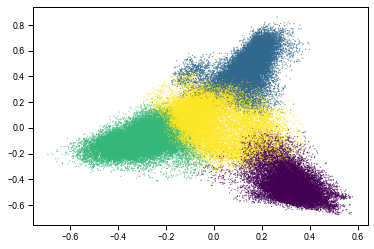

In [252]:
plt.scatter(
    sample_decomposed[:, 0],
    sample_decomposed[:, 1],
    c=sample_df['ClassPredicted'],
    s=0.1,
)

/tmp/ipykernel_2946542/285791921.py:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(


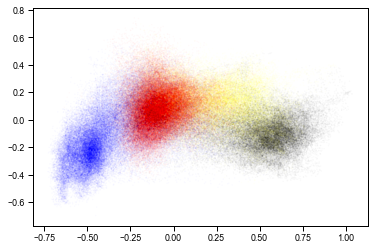

In [253]:
plt.scatter(
    balbc_decomposed[:, 1],
    balbc_decomposed[:, 2],
    c=balbc_samples_df['Compartment'].apply(lambda x: COMPARTMENT_TO_COLOR[x]),
    alpha=0.01,
    s=1,
    cmap=colors_cc,
)

In [254]:
classes_dict

{0: 1, 1: 0, 2: 3, 3: 2}

In [255]:
sample_amis, sample_f1s, sample_aris

([0.5955356430176777, 0.5580510273574404, 0.5716285289083989],
 [0.7907627415551474, 0.7465165595655803, 0.7479060857780087],
 [0.6064080739815768, 0.5514528642831797, 0.5498126695050306])

In [1052]:
f1_scores = {
    'Cellohood': sample_f1s,
    'Cellcharter': [0.6382120375905547, 0.40998378846220024, 0.5308355995170531],
    'CytoCommunity': [0.649, 0.679, 0.709],
    'Spatial-LDA': [0.505, 0.512, 0.644],
    'UTAG': [0.57, 0.6, 0.621],
    'STAGATE': [0.541, 0.568, 0.571],
    'BayesSpace': [0.492, 0.503, 0.59],
    'stLearn': [0.509, 0.517, 0.525]
}

In [1053]:
ami_scores = {
    'Cellohood': sample_amis,
    'Cellcharter': [0.5392592234616603, 0.5866669217507666, 0.5340765520952658],
    'CytoCommunity': [0.507, 0.541, 0.554],
    'Spatial-LDA': [0.408, 0.42, 0.502],
    'UTAG': [0.535, 0.565, 0.592],
    'STAGATE': [0.385, 0.431, 0.441],
    'BayesSpace': [0.34, 0.389, 0.418],
    'stLearn': [0.287, 0.308, 0.321],
}

In [1054]:
from scipy.stats import ttest_rel, ttest_ind

In [1055]:
ttest_rel([0.649, 0.679, 0.709], [0.57, 0.6, 0.621])

TtestResult(statistic=27.333333333333655, pvalue=0.0013358076463885378, df=2)

In [1056]:
def gen_permuations():
    perms = []
    for i in range(3):
        first = i
        for j in range(3):
            if j == first:
                continue
            second = j
            for k in range(3):
                if k in [first, second]:
                    continue
                perms.append((first, second, k))
    return perms

## Images With Spatial Directions

In [1057]:
cyto_1 = plt.imread('/raid/immucan/immuw/tumorhood/tumorhood_bc/notebooks/cello_fig/Cyto-Balbc3.png')
cyto_2 = plt.imread('/raid/immucan/immuw/tumorhood/tumorhood_bc/notebooks/cello_fig/Cyto-Balbc2.png')
cyto_3 = plt.imread('/raid/immucan/immuw/tumorhood/tumorhood_bc/notebooks/cello_fig/Cyto-Balbc1.png')

In [1058]:
utag_1 = plt.imread('/raid/immucan/immuw/tumorhood/tumorhood_bc/notebooks/cello_fig/Utag-Balbc1.png')
utag_2 = plt.imread('/raid/immucan/immuw/tumorhood/tumorhood_bc/notebooks/cello_fig/Utag-Balbc2.png')
utag_3 = plt.imread('/raid/immucan/immuw/tumorhood/tumorhood_bc/notebooks/cello_fig/Utag-Balbc3.png')

In [1059]:
import seaborn as sns
import matplotlib


# Plotting
PLOTTING_DPI = 300
sns.set_context("paper", rc={"font.size": 6, "axes.titlesize":6,"axes.labelsize":6})  
plt.rcParams['legend.title_fontsize'] = 6
plt.rcParams['legend.fontsize'] = 6

matplotlib.font_manager.fontManager.addfont('/raid/immucan/immuw/Arial.ttf')  # if you need to add the font file
plt.rcParams['font.family'] = 'Arial'

## Cellohood vs GT and other methods

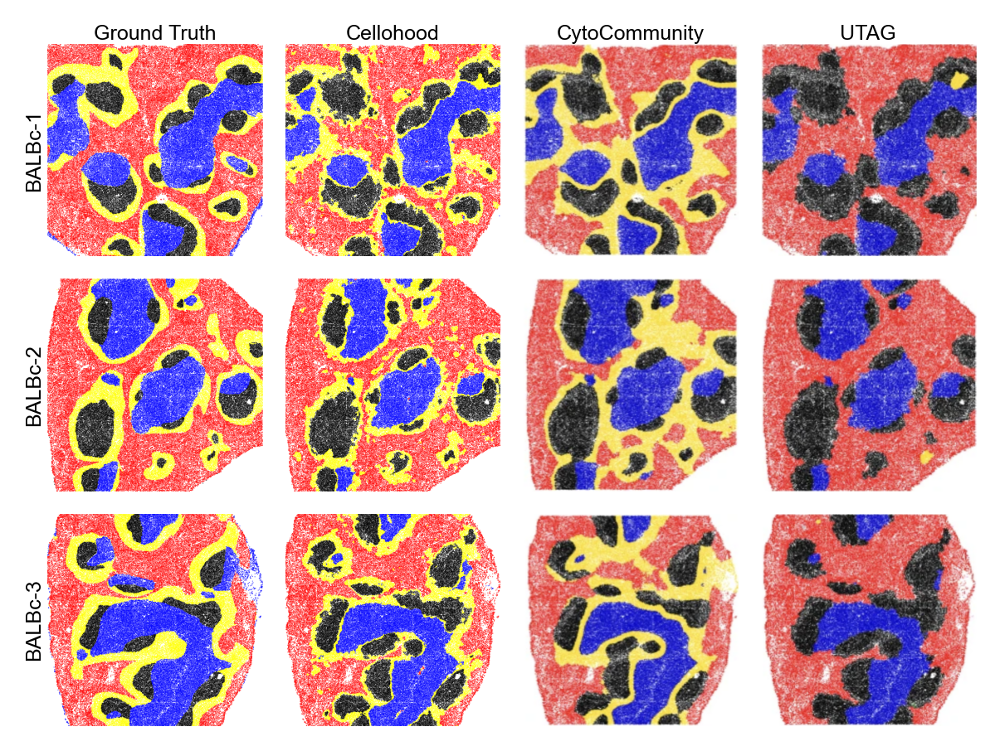

In [1060]:
plt.figure(figsize=(4, 3), dpi=300)

SCATTER_ALPHA = 0.6

plt.subplot(3, 4, 1)
balbc1_all_df = balbc_samples_df_all[balbc_samples_df_all['sample'] == 'BALBc-1']
balbc1_df = balbc1_all_df[balbc1_all_df['Compartment'].apply(lambda x: x in compartments[:4])]

plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=balbc1_df['Compartment'].apply(lambda x: colors_cc(compartments.index(x))),
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.title('Ground Truth', size=6, pad=1)
plt.ylabel('BALBc-1', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])


plt.subplot(3, 4, 2)

balbc1_preds = sample_to_predictions['BALBc-1'][
    balbc1_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=[colors_cc(x) for x in balbc1_preds],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.title('Cellohood', size=6, pad=1)

ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])

plt.subplot(3, 4, 3)

plt.imshow(cyto_1, aspect='auto')
plt.title('CytoCommunity', size=6, pad=1)
plt.axis('off')


plt.subplot(3, 4, 4)

plt.imshow(utag_1, aspect='auto')
plt.title('UTAG', size=6, pad=1)
plt.axis('off')

plt.subplot(3, 4, 5)
balbc2_all_df = balbc_samples_df_all[balbc_samples_df_all['sample'] == 'BALBc-2']
balbc2_df = balbc2_all_df[balbc2_all_df['Compartment'].apply(lambda x: x in compartments[:4])]

plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=balbc2_df['Compartment'].apply(lambda x: colors_cc(compartments.index(x))),
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.ylabel('BALBc-2', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 4, 6)

balbc2_preds = sample_to_predictions['BALBc-2'][
    balbc2_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=[colors_cc(x) for x in balbc2_preds],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)

ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 4, 7)

plt.imshow(cyto_2, aspect='auto')
plt.axis('off')

plt.subplot(3, 4, 8)

plt.imshow(utag_2, aspect='auto')
plt.axis('off')

plt.subplot(3, 4, 9)
balbc3_all_df = balbc_samples_df_all[balbc_samples_df_all['sample'] == 'BALBc-3']
balbc3_df = balbc3_all_df[balbc3_all_df['Compartment'].apply(lambda x: x in compartments[:4])]

plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=balbc3_df['Compartment'].apply(lambda x: colors_cc(compartments.index(x))),
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.ylabel('BALBc-3', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc3_df['tile.X'].min(), balbc3_df['tile.X'].max()])
ax.set_ylim([balbc3_df['tile.Y'].min(), balbc3_df['tile.Y'].max()])

plt.subplot(3, 4, 10)

balbc3_preds = sample_to_predictions['BALBc-3'][
    balbc3_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=[colors_cc(x) for x in balbc3_preds],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)

ax = plt.gca()
ax.set_aspect('auto')
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_xlim([balbc3_df['tile.X'].min(), balbc3_df['tile.X'].max()])
ax.set_ylim([balbc3_df['tile.Y'].min(), balbc3_df['tile.Y'].max()])

plt.subplot(3, 4, 11)

plt.imshow(cyto_3, aspect='auto')
plt.axis('off')

plt.subplot(3, 4, 12)

plt.imshow(utag_3, aspect='auto')
plt.axis('off')

plt.tight_layout()

## Same + Principal Latent Dimensions

/tmp/ipykernel_2946542/3559642753.py:80: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(
/tmp/ipykernel_2946542/3559642753.py:206: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(
/tmp/ipykernel_2946542/3559642753.py:331: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(


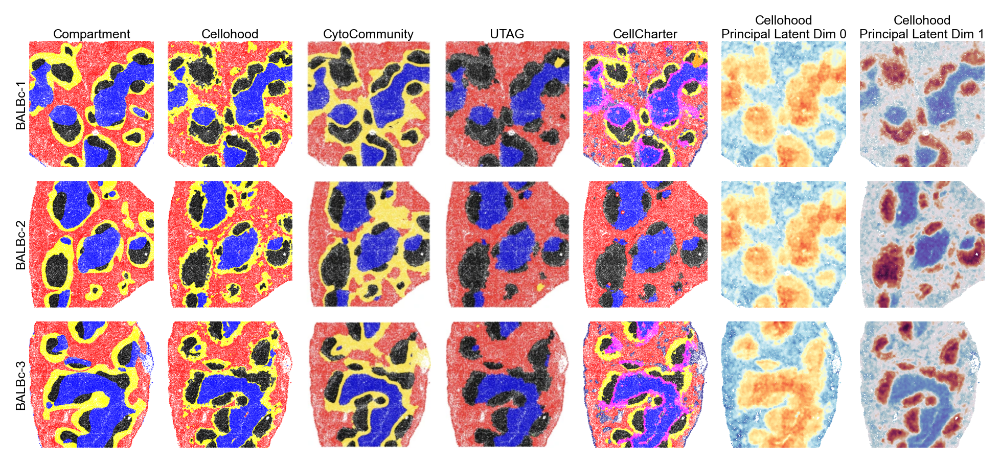

In [1119]:
plt.figure(figsize=(6.5, 3), dpi=300)

SCATTER_ALPHA = 0.6

plt.subplot(3, 7, 1)
balbc1_all_df = balbc_samples_df_all[balbc_samples_df_all['sample'] == 'BALBc-1']
balbc1_df = balbc1_all_df[balbc1_all_df['Compartment'].apply(lambda x: x in compartments[:4])]

plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=balbc1_df['Compartment'].apply(lambda x: colors_cc(compartments.index(x))),
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.title('Compartment', size=6, pad=1)
plt.ylabel('BALBc-1', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])


plt.subplot(3, 7, 2)

balbc1_preds = sample_to_predictions['BALBc-1'][
    balbc1_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=[colors_cc(x) for x in balbc1_preds],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.title('Cellohood', size=6, pad=1)

ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])

plt.subplot(3, 7, 3)

plt.imshow(cyto_1, aspect='auto')
plt.title('CytoCommunity', size=6, pad=1)
plt.axis('off')


plt.subplot(3, 7, 4)

plt.imshow(utag_1, aspect='auto')
plt.title('UTAG', size=6, pad=1)
plt.axis('off')

pd_0_min = balbc_decomposed[:, 0].min()
pd_1_min = balbc_decomposed[:, 1].min()
pd_0_max = balbc_decomposed[:, 0].max()
pd_1_max = balbc_decomposed[:, 1].max()
pd_0_lim = max(abs(pd_0_min), abs(pd_0_max))
pd_1_lim = max(abs(pd_1_min), abs(pd_1_max))

plt.subplot(3, 7, 5)

balbc1_all_decomposed = balbc_decomposed[balbc_samples_df_all['sample'] == 'BALBc-1']
balbc1_decomposed = balbc1_all_decomposed[balbc1_all_df['CompartmentValidInt'].apply(lambda x: x < 4)]
balbc1_cc = cellcharter_preds[cellcharter_preds['sample'] == 'BALBc-1']

plt.scatter(
    x=balbc1_cc['pos_x'],
    y=balbc1_cc['pos_y'],
    c=balbc1_cc['pred'].apply(lambda x: b1_cc_to_color[x]),
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
    cmap='tab10',
)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_cc['pos_x'].min(), balbc1_cc['pos_x'].max()])
ax.set_ylim([balbc1_cc['pos_y'].min(), balbc1_cc['pos_y'].max()])
plt.title('CellCharter', size=6, pad=1)

plt.subplot(3, 7, 6)


plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=balbc1_decomposed[:, 0],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_0_lim,
    vmax=pd_0_lim,
    cmap='RdYlBu_r',
)
plt.title('Cellohood\nPrincipal Latent Dim 0', size=6, pad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])

plt.subplot(3, 7, 7)

plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=balbc1_decomposed[:, 1],
    s=0.01,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_1_lim,
    vmax=pd_1_lim,
    cmap='twilight_shifted',
)
plt.title('Cellohood\nPrincipal Latent Dim 1', size=6, pad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])

plt.subplot(3, 7, 8)

plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=balbc2_df['Compartment'].apply(lambda x: colors_cc(compartments.index(x))),
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.ylabel('BALBc-2', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 7, 9)

balbc2_preds = sample_to_predictions['BALBc-2'][
    balbc2_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=[colors_cc(x) for x in balbc2_preds],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)

ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 7, 10)

plt.imshow(cyto_2, aspect='auto')
plt.axis('off')

plt.subplot(3, 7, 11)

plt.imshow(utag_2, aspect='auto')
plt.axis('off')

plt.subplot(3, 7, 12)

balbc2_all_decomposed = balbc_decomposed[balbc_samples_df_all['sample'] == 'BALBc-2']
balbc2_decomposed = balbc2_all_decomposed[balbc2_all_df['CompartmentValidInt'].apply(lambda x: x < 4)]
balbc2_cc = cellcharter_preds[cellcharter_preds['sample'] == 'BALBc-2']

plt.scatter(
    x=balbc2_cc['pos_x'],
    y=balbc2_cc['pos_y'],
    c=balbc2_cc['pred'].apply(lambda x: b2_cc_to_color[x]),
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
    cmap='tab10',
)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc2_cc['pos_x'].min(), balbc2_cc['pos_x'].max()])
ax.set_ylim([balbc2_cc['pos_y'].min(), balbc2_cc['pos_y'].max()])

plt.subplot(3, 7, 13)


plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=balbc1_decomposed[:, 0],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_0_lim,
    vmax=pd_0_lim,
    cmap='RdYlBu_r',
)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 7, 14)

plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=balbc2_decomposed[:, 1],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_1_lim,
    vmax=pd_1_lim,
    cmap='twilight_shifted',
)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])

plt.subplot(3, 7, 15)
balbc3_all_df = balbc_samples_df_all[balbc_samples_df_all['sample'] == 'BALBc-3']
balbc3_df = balbc3_all_df[balbc3_all_df['Compartment'].apply(lambda x: x in compartments[:4])]

plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=balbc3_df['Compartment'].apply(lambda x: colors_cc(compartments.index(x))),
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.ylabel('BALBc-3', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc3_df['tile.X'].min(), balbc3_df['tile.X'].max()])
ax.set_ylim([balbc3_df['tile.Y'].min(), balbc3_df['tile.Y'].max()])

plt.subplot(3, 7, 16)

balbc3_preds = sample_to_predictions['BALBc-3'][
    balbc3_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=[colors_cc(x) for x in balbc3_preds],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)

ax = plt.gca()
ax.set_aspect('auto')
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_xlim([balbc3_df['tile.X'].min(), balbc3_df['tile.X'].max()])
ax.set_ylim([balbc3_df['tile.Y'].min(), balbc3_df['tile.Y'].max()])

plt.subplot(3, 7, 17)

plt.imshow(cyto_3, aspect='auto')
plt.axis('off')

plt.subplot(3, 7, 18)

plt.imshow(utag_3, aspect='auto')
plt.axis('off')

plt.subplot(3, 7, 19)

balbc3_all_decomposed = balbc_decomposed[balbc_samples_df_all['sample'] == 'BALBc-3']
balbc3_decomposed = balbc3_all_decomposed[balbc3_all_df['CompartmentValidInt'].apply(lambda x: x < 4)]
balbc3_cc = cellcharter_preds[cellcharter_preds['sample'] == 'BALBc-3']

plt.scatter(
    x=balbc3_cc['pos_x'],
    y=balbc3_cc['pos_y'],
    c=balbc3_cc['pred'].apply(lambda x: b3_cc_to_color[x]),
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
    cmap='tab10',
)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc3_cc['pos_x'].min(), balbc3_cc['pos_x'].max()])
ax.set_ylim([balbc3_cc['pos_y'].min(), balbc3_cc['pos_y'].max()])
#ax.set_aspect('auto')

#ax.set_xlabel('P. Latent Dim 0', size=6, labelpad=1)
#ax.set_ylabel('P. Latent Dim 1', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
pos = ax.get_position()
# Create a new position with increased margins
new_pos = [pos.x0 + 0.012, pos.y0, pos.width - 0.024, pos.height]
# Set the new position
ax.set_position(new_pos)
# ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
# ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 7, 20)


plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=balbc3_decomposed[:, 0],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_0_lim,
    vmax=pd_0_lim,
    cmap='RdYlBu_r',
)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 7, 21)

plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=balbc3_decomposed[:, 1],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_1_lim,
    vmax=pd_1_lim,
    cmap='twilight_shifted',
)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])


plt.tight_layout()
#plt.subplots_adjust(=0.1)

In [1062]:
#COMPARTMENT_TO_COLOR['B-zone'] = mcolors.BASE_COLORS['k']
#COMPARTMENT_TO_COLOR['PALS'] = mcolors.BASE_COLORS['b']
#COMPARTMENT_TO_COLOR['marginal zone'] = mcolors.CSS4_COLORS['yellow']
#COMPARTMENT_TO_COLOR['red pulp'] = mcolors.CSS4_COLORS['red']

b1_cc_to_color = {
    0: mcolors.CSS4_COLORS['navy'],
    1: mcolors.CSS4_COLORS['magenta'],
    2: mcolors.CSS4_COLORS['red'],
    3: mcolors.CSS4_COLORS['blue'],
    4: mcolors.CSS4_COLORS['yellow'],
    5: mcolors.BASE_COLORS['k'],
    6: mcolors.CSS4_COLORS['orange'],
}

b2_cc_to_color = {
    0: mcolors.CSS4_COLORS['red'],
    1: mcolors.CSS4_COLORS['blue'],
    2: mcolors.CSS4_COLORS['black'],
}

b3_cc_to_color = {
    0: mcolors.CSS4_COLORS['black'],
    1: mcolors.CSS4_COLORS['magenta'],
    2: mcolors.CSS4_COLORS['red'],
    3: mcolors.CSS4_COLORS['blue'],
    4: mcolors.CSS4_COLORS['yellow'],
    5: mcolors.CSS4_COLORS['navy'],
}

In [1063]:
Counter(balbc3_cc['pred'])

Counter({2: 21891, 1: 12820, 4: 11311, 3: 15443, 5: 5844, 0: 13664})

/tmp/ipykernel_2946542/2108723260.py:79: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'vmin', 'vmax' will be ignored
  plt.scatter(
/tmp/ipykernel_2946542/2108723260.py:99: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2946542/2108723260.py:101: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_2946542/2108723260.py:214: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(
/tmp/ipykernel_2946542/2108723260.py:231: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2946542/2108723260.py:233: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_29465

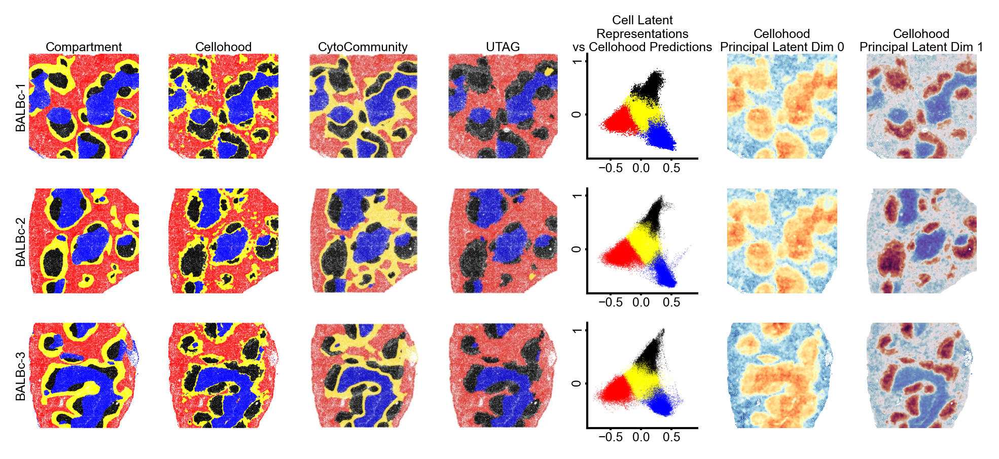

In [1118]:
plt.figure(figsize=(6.5, 3), dpi=300)

SCATTER_ALPHA = 0.6

plt.subplot(3, 7, 1)
balbc1_all_df = balbc_samples_df_all[balbc_samples_df_all['sample'] == 'BALBc-1']
balbc1_df = balbc1_all_df[balbc1_all_df['Compartment'].apply(lambda x: x in compartments[:4])]

plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=balbc1_df['Compartment'].apply(lambda x: colors_cc(compartments.index(x))),
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.title('Compartment', size=6, pad=1)
plt.ylabel('BALBc-1', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])


plt.subplot(3, 7, 2)

balbc1_preds = sample_to_predictions['BALBc-1'][
    balbc1_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=[colors_cc(x) for x in balbc1_preds],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.title('Cellohood', size=6, pad=1)

ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])

plt.subplot(3, 7, 3)

plt.imshow(cyto_1, aspect='auto')
plt.title('CytoCommunity', size=6, pad=1)
plt.axis('off')


plt.subplot(3, 7, 4)

plt.imshow(utag_1, aspect='auto')
plt.title('UTAG', size=6, pad=1)
plt.axis('off')

pd_0_min = balbc_decomposed[:, 0].min()
pd_1_min = balbc_decomposed[:, 1].min()
pd_0_max = balbc_decomposed[:, 0].max()
pd_1_max = balbc_decomposed[:, 1].max()
pd_0_lim = max(abs(pd_0_min), abs(pd_0_max))
pd_1_lim = max(abs(pd_1_min), abs(pd_1_max))

plt.subplot(3, 7, 5)

balbc1_all_decomposed = balbc_decomposed[balbc_samples_df_all['sample'] == 'BALBc-1']
balbc1_decomposed = balbc1_all_decomposed[balbc1_all_df['CompartmentValidInt'].apply(lambda x: x < 4)]

plt.scatter(
    x=balbc1_decomposed[:, 0],
    y=balbc1_decomposed[:, 1],
    c=[colors_cc(x) for x in balbc1_preds],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_1_lim,
    vmax=pd_1_lim,
    cmap='twilight_shifted',
)
plt.title('Cell Latent\nRepresentations\nvs Cellohood Predictions', size=6, pad=1)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
#ax.set_xlabel('P. Latent Dim 0', size=6, labelpad=1)
#ax.set_ylabel('P. Latent Dim 1', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
# ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
# ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 7, 6)


plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=balbc1_decomposed[:, 0],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_0_lim,
    vmax=pd_0_lim,
    cmap='RdYlBu_r',
)
plt.title('Cellohood\nPrincipal Latent Dim 0', size=6, pad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])

plt.subplot(3, 7, 7)

plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=balbc1_decomposed[:, 1],
    s=0.01,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_1_lim,
    vmax=pd_1_lim,
    cmap='twilight_shifted',
)
plt.title('Cellohood\nPrincipal Latent Dim 1', size=6, pad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])

plt.subplot(3, 7, 8)


plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=balbc2_df['Compartment'].apply(lambda x: colors_cc(compartments.index(x))),
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.ylabel('BALBc-2', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 7, 9)

balbc2_preds = sample_to_predictions['BALBc-2'][
    balbc2_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=[colors_cc(x) for x in balbc2_preds],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)

ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 7, 10)

plt.imshow(cyto_2, aspect='auto')
plt.axis('off')

plt.subplot(3, 7, 11)

plt.imshow(utag_2, aspect='auto')
plt.axis('off')

plt.subplot(3, 7, 12)

balbc2_all_decomposed = balbc_decomposed[balbc_samples_df_all['sample'] == 'BALBc-2']
balbc2_decomposed = balbc2_all_decomposed[balbc2_all_df['CompartmentValidInt'].apply(lambda x: x < 4)]

plt.scatter(
    x=balbc2_decomposed[:, 0],
    y=balbc2_decomposed[:, 1],
    c=[colors_cc(x) for x in balbc2_preds],
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
    cmap='twilight_shifted',
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
#ax.set_xlabel('P. Latent Dim 0', size=6, labelpad=1)
#ax.set_ylabel('P. Latent Dim 1', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
# ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
# ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 7, 13)


plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=balbc1_decomposed[:, 0],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_0_lim,
    vmax=pd_0_lim,
    cmap='RdYlBu_r',
)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 7, 14)

plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=balbc2_decomposed[:, 1],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_1_lim,
    vmax=pd_1_lim,
    cmap='twilight_shifted',
)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])

plt.subplot(3, 7, 15)
balbc3_all_df = balbc_samples_df_all[balbc_samples_df_all['sample'] == 'BALBc-3']
balbc3_df = balbc3_all_df[balbc3_all_df['Compartment'].apply(lambda x: x in compartments[:4])]

plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=balbc3_df['Compartment'].apply(lambda x: colors_cc(compartments.index(x))),
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.ylabel('BALBc-3', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc3_df['tile.X'].min(), balbc3_df['tile.X'].max()])
ax.set_ylim([balbc3_df['tile.Y'].min(), balbc3_df['tile.Y'].max()])

plt.subplot(3, 7, 16)

balbc3_preds = sample_to_predictions['BALBc-3'][
    balbc3_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=[colors_cc(x) for x in balbc3_preds],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)

ax = plt.gca()
ax.set_aspect('auto')
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_xlim([balbc3_df['tile.X'].min(), balbc3_df['tile.X'].max()])
ax.set_ylim([balbc3_df['tile.Y'].min(), balbc3_df['tile.Y'].max()])

plt.subplot(3, 7, 17)

plt.imshow(cyto_3, aspect='auto')
plt.axis('off')

plt.subplot(3, 7, 18)

plt.imshow(utag_3, aspect='auto')
plt.axis('off')

plt.subplot(3, 7, 19)

balbc3_all_decomposed = balbc_decomposed[balbc_samples_df_all['sample'] == 'BALBc-3']
balbc3_decomposed = balbc3_all_decomposed[balbc3_all_df['CompartmentValidInt'].apply(lambda x: x < 4)]

plt.scatter(
    x=balbc3_decomposed[:, 0],
    y=balbc3_decomposed[:, 1],
    c=[colors_cc(x) for x in balbc3_preds],
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
    cmap='twilight_shifted',
)
ax = plt.gca()
#ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax.xaxis.set_tick_params(size=1, pad=1)
#ax.set_xlabel('P. Latent Dim 0', size=6, labelpad=1)
#ax.set_ylabel('P. Latent Dim 1', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
pos = ax.get_position()
# Create a new position with increased margins
new_pos = [pos.x0 + 0.012, pos.y0, pos.width - 0.024, pos.height]
# Set the new position
ax.set_position(new_pos)
# ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
# ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 7, 20)


plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=balbc3_decomposed[:, 0],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_0_lim,
    vmax=pd_0_lim,
    cmap='RdYlBu_r',
)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

plt.subplot(3, 7, 21)

plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=balbc3_decomposed[:, 1],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_1_lim,
    vmax=pd_1_lim,
    cmap='twilight_shifted',
)
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc1_df['tile.X'].min(), balbc1_df['tile.X'].max()])
ax.set_ylim([balbc1_df['tile.Y'].min(), balbc1_df['tile.Y'].max()])


plt.tight_layout()
#plt.subplots_adjust(=0.1)

In [1065]:
cellcharter_preds = pandas.read_csv('Cellcharter_preds.csv')

In [1066]:
cellcharter_preds

,Unnamed: 0,pos_x,pos_y,pred,sample
0,0,189128,833216,1,BALBc-1
1,1,442740,866116,2,BALBc-1
2,2,444056,144196,2,BALBc-1
3,3,191760,961620,3,BALBc-1
4,4,697856,1516032,2,BALBc-1
...,...,...,...,...,...
245275,245275,1182520,495192,3,BALBc-3
245276,245276,1191356,342160,3,BALBc-3
245277,245277,1029300,1701776,1,BALBc-3
245278,245278,439544,1648008,5,BALBc-3


## Macro F1 / AMI Plots

In [1067]:
method_cmap = plt.get_cmap('tab20', 7)

f1s_df = pandas.DataFrame(f1_scores)
amis_df = pandas.DataFrame(ami_scores)

def AnnoMe(x1, x2, y, txt, h=0.005, offset=0, col='gray', fontsize=5, lw=0.5):
    plt.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=lw, c=col)
    plt.text((x1+x2)*.5, y+h - offset, txt, ha='center', va='bottom', c=col, fontsize=fontsize)
    
    
def get_stars_from_pval(pval):
    pval_adj = f''
    if pval >= 0.01:
        pval_adj += f'={round(pval, 2)}'
    elif pval >= 0.001:
        pval_adj += f'={round(pval, 3)}'
    else:
        pval_adj += '<0.001'
    result = f'p{pval_adj} ('
    if pval < 0.05:
        result += '*'
    if pval < 0.01:
        result += '*'
    if pval < 0.001:
        result += '*'
    if pval >= 0.05:
        result += 'ns'
    return result + ')'

In [1068]:
f1s_df

,Cellohood,Cellcharter,CytoCommunity,Spatial-LDA,UTAG,STAGATE,BayesSpace,stLearn
0,0.790763,0.638212,0.649,0.505,0.570,0.541,0.492,0.509
1,0.746517,0.409984,0.679,0.512,0.600,0.568,0.503,0.517
2,0.747906,0.530836,0.709,0.644,0.621,0.571,0.590,0.525


In [1069]:
ALTERNATIVE = 'greater'

f1s_p_vals = numpy.zeros((len(f1s_df.columns), len(f1s_df.columns)))
amis_p_vals = numpy.zeros((len(f1s_df.columns), len(f1s_df.columns)))

for l_ind, l_col in enumerate(f1s_df.columns):
    for r_ind, r_col in enumerate(f1s_df.columns):
        f1s_p_vals[l_ind, r_ind] = ttest_ind(
            f1s_df[l_col], f1s_df[r_col], alternative=ALTERNATIVE, equal_var=True).pvalue
        amis_p_vals[l_ind, r_ind] = ttest_ind(
            amis_df[l_col], amis_df[r_col], alternative=ALTERNATIVE, equal_var=False).pvalue

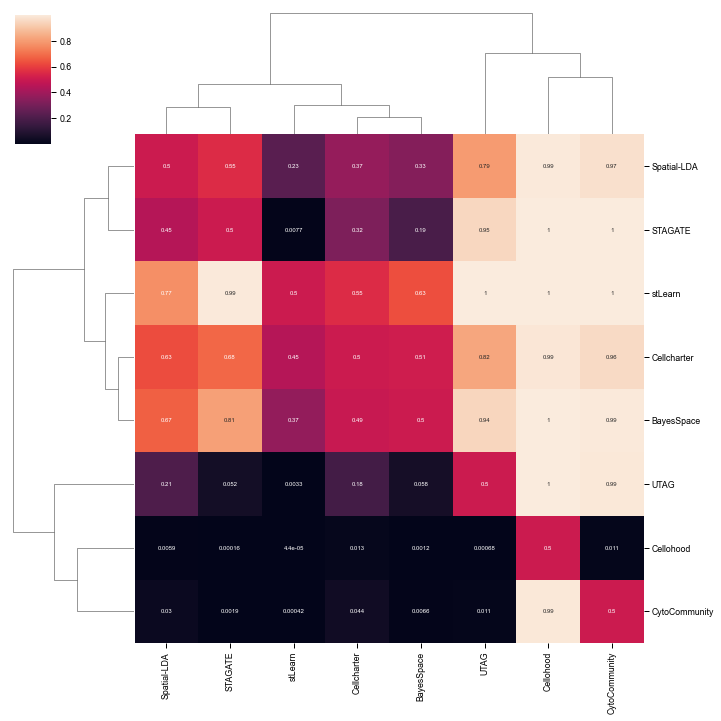

In [1070]:
sns.clustermap(f1s_p_vals, xticklabels=f1s_df.columns, yticklabels=f1s_df.columns, annot=True)

/tmp/ipykernel_2946542/304797205.py:5: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter([ind_] * 3, f1s_df[col], c=method_cmap(ind_), s=20, alpha=0.4)
/tmp/ipykernel_2946542/304797205.py:6: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter([ind_], [f1s_df[col].mean()], marker='_', c=method_cmap(ind_), s=50)
/tmp/ipykernel_2946542/304797205.py:31: UserWarning: *c* argument looks like a single numeric RGB or R

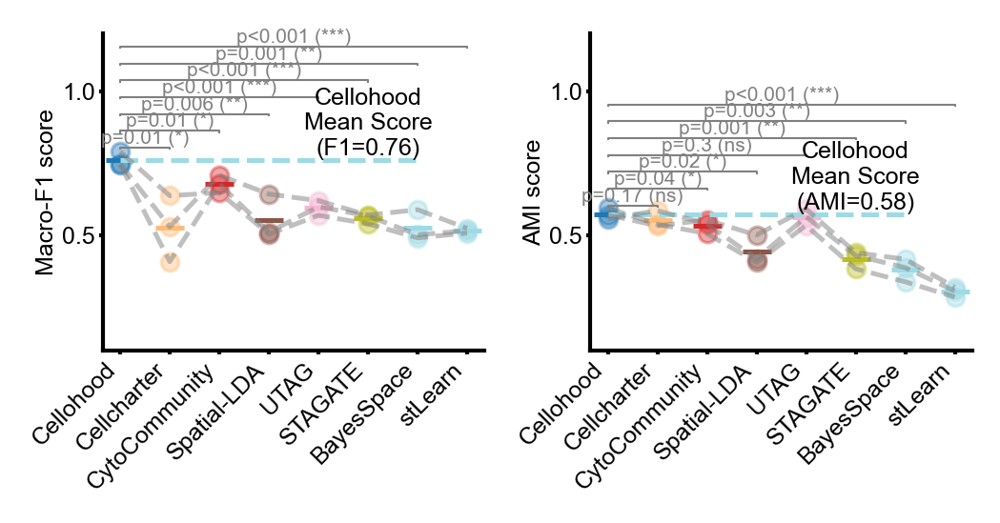

In [1071]:
plt.figure(figsize=(3.5, 1.8), dpi=300)

plt.subplot(1, 2, 1)
for ind_, col in enumerate(f1s_df.columns):
    plt.scatter([ind_] * 3, f1s_df[col], c=method_cmap(ind_), s=20, alpha=0.4)
    plt.scatter([ind_], [f1s_df[col].mean()], marker='_', c=method_cmap(ind_), s=50)
    
    
plt.plot([0, 6], [f1s_df['Cellohood'].mean()] * 2, linestyle='dashed', c=method_cmap(ind_))
plt.text(5, f1s_df['Cellohood'].mean(), f'Cellohood\nMean Score\n(F1={round(f1s_df["Cellohood"].mean(), 2)})', ha='center', va='bottom')

for other, x in enumerate(numpy.linspace(0.8, 1.15, 7)):
    AnnoMe(0, other + 1, x, get_stars_from_pval(f1s_p_vals[0, other + 1]))
    
plt.ylim([0.1, 1.2])
plt.plot(f1s_df.loc[0], c='gray', linestyle='dashed', alpha=0.5)
plt.plot(f1s_df.loc[1], c='gray', linestyle='dashed', alpha=0.5)
plt.plot(f1s_df.loc[2], c='gray', linestyle='dashed', alpha=0.5)
plt.xticks(rotation=45, size=6, ha='right')
plt.yticks(size=6)
plt.ylabel('Macro-F1 score', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'right']].set_visible(False)
ax.yaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)


plt.subplot(1, 2, 2)

for ind_, col in enumerate(f1s_df.columns):
    plt.scatter([ind_] * 3, amis_df[col], c=method_cmap(ind_), s=20, alpha=0.4)
    plt.scatter([ind_], [amis_df[col].mean()], marker='_', c=method_cmap(ind_), s=50)
    
plt.plot([0, 6], [amis_df['Cellohood'].mean()] * 2, linestyle='dashed', c=method_cmap(ind_))
plt.text(5, amis_df['Cellohood'].mean(), f'Cellohood\nMean Score\n(AMI={round(amis_df["Cellohood"].mean(), 2)})', ha='center', va='bottom')
plt.ylim([0, 1])
    
for other, x in enumerate(numpy.linspace(0.6, 0.95, len(amis_p_vals) - 1)):
    AnnoMe(0, other + 1, x, get_stars_from_pval(amis_p_vals[0, other + 1]))
    
plt.ylim([0.1, 1.2])
plt.plot(amis_df.loc[0], c='gray', linestyle='dashed', alpha=0.5)
plt.plot(amis_df.loc[1], c='gray', linestyle='dashed', alpha=0.5)
plt.plot(amis_df.loc[2], c='gray', linestyle='dashed', alpha=0.5)
plt.xticks(rotation=45, size=6, ha='right')
plt.yticks(size=6)
plt.ylabel('AMI score', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'right']].set_visible(False)
ax.yaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)

plt.tight_layout()

## Latent Representations

/tmp/ipykernel_2946542/2033533535.py:3: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(
/tmp/ipykernel_2946542/2033533535.py:21: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2946542/2033533535.py:23: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


Text(0.5, 1.0, 'Cell Latent\nRepresentations\nvs Compartment')

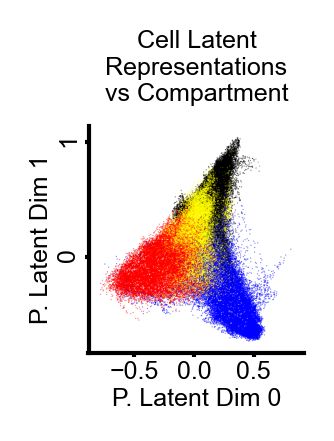

In [1117]:
plt.figure(figsize=(6.5 / 7, 1), dpi=300)

plt.scatter(
    x=balbc_decomposed[:, 0],
    y=balbc_decomposed[:, 1],
    c=[colors_cc(x) for x in balbc_samples_df_all['CompartmentValidInt']],
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
    cmap='twilight_shifted',
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('P. Latent Dim 0', size=6, labelpad=1)
ax.set_ylabel('P. Latent Dim 1', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('Cell Latent\nRepresentations\nvs Compartment', size=6)

/tmp/ipykernel_2946542/2085749235.py:3: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(
/tmp/ipykernel_2946542/2085749235.py:21: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2946542/2085749235.py:23: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


Text(0.5, 1.0, 'Cell Latent\nRepresentations\nvs Compartment')

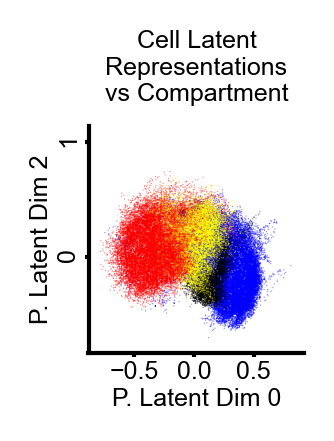

In [1116]:
plt.figure(figsize=(6.5 / 7, 1), dpi=300)

plt.scatter(
    x=balbc_decomposed[:, 0],
    y=balbc_decomposed[:, 2],
    c=[colors_cc(x) for x in balbc_samples_df_all['CompartmentValidInt']],
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
    cmap='twilight_shifted',
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('P. Latent Dim 0', size=6, labelpad=1)
ax.set_ylabel('P. Latent Dim 2', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('Cell Latent\nRepresentations\nvs Compartment', size=6)

/tmp/ipykernel_2946542/888854300.py:3: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(
/tmp/ipykernel_2946542/888854300.py:21: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2946542/888854300.py:23: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


Text(0.5, 1.0, 'Cell Latent\nRepresentations\nvs Ground Truth')

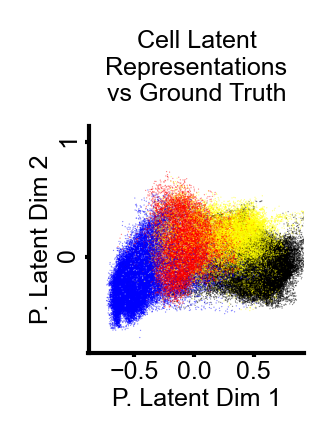

In [1022]:
plt.figure(figsize=(6.5 / 7, 1), dpi=300)

plt.scatter(
    x=balbc_decomposed[:, 1],
    y=balbc_decomposed[:, 2],
    c=[colors_cc(x) for x in balbc_samples_df_all['CompartmentValidInt']],
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
    cmap='twilight_shifted',
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('P. Latent Dim 1', size=6, labelpad=1)
ax.set_ylabel('P. Latent Dim 2', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('Cell Latent\nRepresentations\nvs Ground Truth', size=6)

/tmp/ipykernel_2946542/3908685094.py:3: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(
/tmp/ipykernel_2946542/3908685094.py:21: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2946542/3908685094.py:23: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


Text(0.5, 1.0, 'Cell Latent\nRepresentations\nvs Ground Truth')

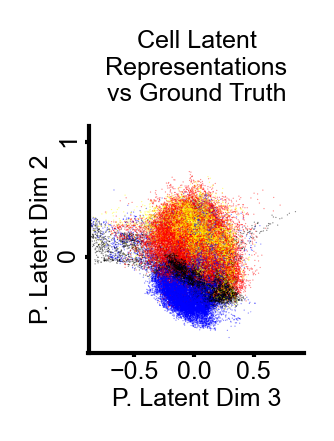

In [1114]:
plt.figure(figsize=(6.5 / 7, 1), dpi=300)

plt.scatter(
    x=balbc_decomposed[:, 3],
    y=balbc_decomposed[:, 2],
    c=[colors_cc(x) for x in balbc_samples_df_all['CompartmentValidInt']],
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
    cmap='twilight_shifted',
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('P. Latent Dim 3', size=6, labelpad=1)
ax.set_ylabel('P. Latent Dim 2', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('Cell Latent\nRepresentations\nvs Ground Truth', size=6)

/tmp/ipykernel_2946542/524282223.py:38: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2946542/524282223.py:40: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


Text(0.5, 1.0, 'vs Lupus')

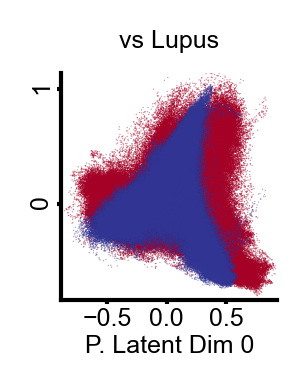

In [66]:
plt.figure(figsize=(6.5 / 7, 1), dpi=300)

random_perm = numpy.random.permutation(decomposed.shape[0])

plt.scatter(
    x=decomposed[bag_cello_df.cell_df['sample'].apply(lambda x: not x.startswith('BALB')), 0],
    y=decomposed[bag_cello_df.cell_df['sample'].apply(lambda x: not x.startswith('BALB')), 1],
    c=[0] * sum(bag_cello_df.cell_df['sample'].apply(lambda x: not x.startswith('BALB'))),
    s=0.01,
    vmin=0,
    vmax=1,
    linewidths=0.2,
    alpha=0.5,
    cmap='RdYlBu',
    label='Healthy',
)
plt.scatter(
    x=decomposed[bag_cello_df.cell_df['sample'].apply(lambda x: x.startswith('BALB')), 0],
    y=decomposed[bag_cello_df.cell_df['sample'].apply(lambda x: x.startswith('BALB')), 1],
    c=[1] * sum(bag_cello_df.cell_df['sample'].apply(lambda x: x.startswith('BALB'))),
    s=0.01,
    vmin=0,
    vmax=1,
    linewidths=0.2,
    alpha=0.5,
    cmap='RdYlBu',
    label='Lupus',
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('P. Latent Dim 0', size=6, labelpad=1)
#ax.set_ylabel('P. Latent Dim 1', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('vs Lupus', size=6)

/tmp/ipykernel_2946542/953669485.py:38: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2946542/953669485.py:40: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


Text(0.5, 1.0, 'vs Lupus')

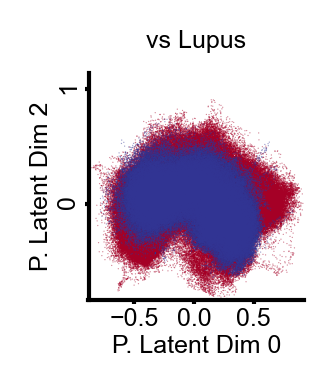

In [1018]:
plt.figure(figsize=(6.5 / 7, 1), dpi=300)

random_perm = numpy.random.permutation(decomposed.shape[0])

plt.scatter(
    x=decomposed[bag_cello_df.cell_df['sample'].apply(lambda x: not x.startswith('BALB')), 0],
    y=decomposed[bag_cello_df.cell_df['sample'].apply(lambda x: not x.startswith('BALB')), 2],
    c=[0] * sum(bag_cello_df.cell_df['sample'].apply(lambda x: not x.startswith('BALB'))),
    s=0.01,
    vmin=0,
    vmax=1,
    linewidths=0.2,
    alpha=0.5,
    cmap='RdYlBu',
    label='Healthy',
)
plt.scatter(
    x=decomposed[bag_cello_df.cell_df['sample'].apply(lambda x: x.startswith('BALB')), 0],
    y=decomposed[bag_cello_df.cell_df['sample'].apply(lambda x: x.startswith('BALB')), 2],
    c=[1] * sum(bag_cello_df.cell_df['sample'].apply(lambda x: x.startswith('BALB'))),
    s=0.01,
    vmin=0,
    vmax=1,
    linewidths=0.2,
    alpha=0.5,
    cmap='RdYlBu',
    label='Lupus',
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('P. Latent Dim 0', size=6, labelpad=1)
ax.set_ylabel('P. Latent Dim 2', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('vs Lupus', size=6)

/tmp/ipykernel_2946542/243729976.py:38: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2946542/243729976.py:40: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


Text(0.5, 1.0, 'vs Lupus')

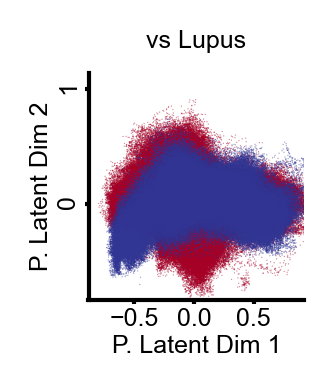

In [1019]:
plt.figure(figsize=(6.5 / 7, 1), dpi=300)

random_perm = numpy.random.permutation(decomposed.shape[0])

plt.scatter(
    x=decomposed[bag_cello_df.cell_df['sample'].apply(lambda x: not x.startswith('BALB')), 1],
    y=decomposed[bag_cello_df.cell_df['sample'].apply(lambda x: not x.startswith('BALB')), 2],
    c=[0] * sum(bag_cello_df.cell_df['sample'].apply(lambda x: not x.startswith('BALB'))),
    s=0.01,
    vmin=0,
    vmax=1,
    linewidths=0.2,
    alpha=0.5,
    cmap='RdYlBu',
    label='Healthy',
)
plt.scatter(
    x=decomposed[bag_cello_df.cell_df['sample'].apply(lambda x: x.startswith('BALB')), 1],
    y=decomposed[bag_cello_df.cell_df['sample'].apply(lambda x: x.startswith('BALB')), 2],
    c=[1] * sum(bag_cello_df.cell_df['sample'].apply(lambda x: x.startswith('BALB'))),
    s=0.01,
    vmin=0,
    vmax=1,
    linewidths=0.2,
    alpha=0.5,
    cmap='RdYlBu',
    label='Lupus',
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('P. Latent Dim 1', size=6, labelpad=1)
ax.set_ylabel('P. Latent Dim 2', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('vs Lupus', size=6)

/tmp/ipykernel_2946542/1730898448.py:38: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2946542/1730898448.py:40: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


Text(0.5, 1.0, 'vs Lupus')

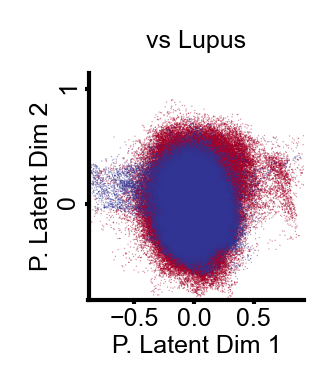

In [1113]:
plt.figure(figsize=(6.5 / 7, 1), dpi=300)

random_perm = numpy.random.permutation(decomposed.shape[0])

plt.scatter(
    x=decomposed[bag_cello_df.cell_df['sample'].apply(lambda x: not x.startswith('BALB')), 3],
    y=decomposed[bag_cello_df.cell_df['sample'].apply(lambda x: not x.startswith('BALB')), 2],
    c=[0] * sum(bag_cello_df.cell_df['sample'].apply(lambda x: not x.startswith('BALB'))),
    s=0.01,
    vmin=0,
    vmax=1,
    linewidths=0.2,
    alpha=0.5,
    cmap='RdYlBu',
    label='Healthy',
)
plt.scatter(
    x=decomposed[bag_cello_df.cell_df['sample'].apply(lambda x: x.startswith('BALB')), 3],
    y=decomposed[bag_cello_df.cell_df['sample'].apply(lambda x: x.startswith('BALB')), 2],
    c=[1] * sum(bag_cello_df.cell_df['sample'].apply(lambda x: x.startswith('BALB'))),
    s=0.01,
    vmin=0,
    vmax=1,
    linewidths=0.2,
    alpha=0.5,
    cmap='RdYlBu',
    label='Lupus',
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('P. Latent Dim 3', size=6, labelpad=1)
ax.set_ylabel('P. Latent Dim 2', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('vs Lupus', size=6)

In [67]:
decomposed.shape, bag_cello_df.cell_df.shape

((734103, 64), (734103, 52))

/tmp/ipykernel_2946542/3842719252.py:20: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2946542/3842719252.py:22: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


Text(0.5, 1.0, 'vs Sample')

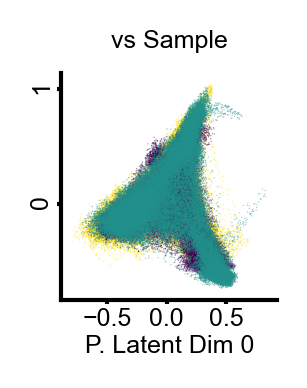

In [68]:
plt.figure(figsize=(6.5 / 7, 1), dpi=300)

plt.scatter(
    x=balbc_decomposed[:, 0],
    y=balbc_decomposed[:, 1],
    c=balbc_samples_df_all['sample'].apply(lambda x: int(x.split('-')[-1])),
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('P. Latent Dim 0', size=6, labelpad=1)
#ax.set_ylabel('P. Latent Dim 1', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('vs Sample', size=6)

/tmp/ipykernel_2946542/2518948338.py:20: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2946542/2518948338.py:22: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


Text(0.5, 1.0, 'vs Sample')

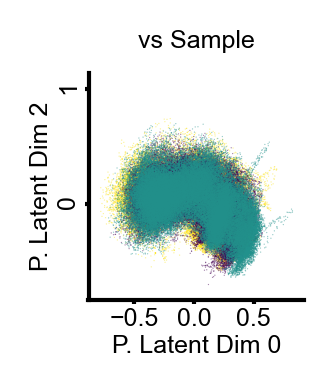

In [1016]:
plt.figure(figsize=(6.5 / 7, 1), dpi=300)

plt.scatter(
    x=balbc_decomposed[:, 0],
    y=balbc_decomposed[:, 2],
    c=balbc_samples_df_all['sample'].apply(lambda x: int(x.split('-')[-1])),
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('P. Latent Dim 0', size=6, labelpad=1)
ax.set_ylabel('P. Latent Dim 2', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('vs Sample', size=6)

/tmp/ipykernel_2946542/1076956983.py:20: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_2946542/1076956983.py:22: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


Text(0.5, 1.0, 'vs Sample')

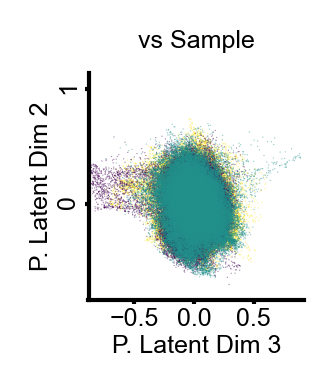

In [1115]:
plt.figure(figsize=(6.5 / 7, 1), dpi=300)

plt.scatter(
    x=balbc_decomposed[:, 3],
    y=balbc_decomposed[:, 2],
    c=balbc_samples_df_all['sample'].apply(lambda x: int(x.split('-')[-1])),
    s=0.01,
    linewidths=0.2,
    alpha=0.5,
)
ax = plt.gca()
ax.set_aspect('auto')
plt.xlim([pd_0_min - 0.1, pd_0_max + 0.1])
plt.ylim([pd_1_min - 0.1, pd_1_max + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('P. Latent Dim 3', size=6, labelpad=1)
ax.set_ylabel('P. Latent Dim 2', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('vs Sample', size=6)

## Compartment Legend

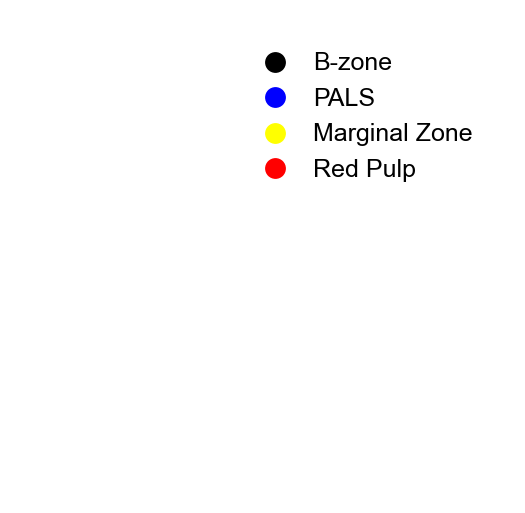

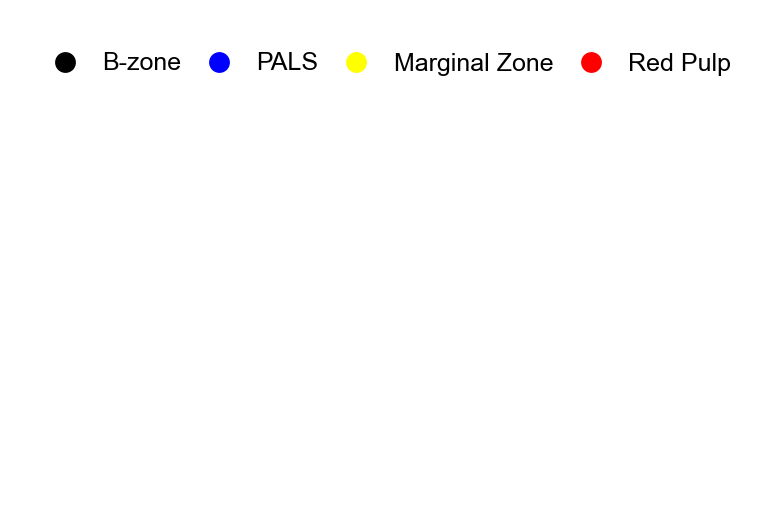

In [69]:
from matplotlib.pyplot import Line2D


legend_elements = [
    Line2D([0], [0], marker='o', markerfacecolor=colors_cc(0), color='w', label='B-zone', markersize=6),
    Line2D([0], [0], marker='o', markerfacecolor=colors_cc(1), color='w', label='PALS', markersize=6),
    Line2D([0], [0], marker='o', markerfacecolor=colors_cc(2), color='w', label='Marginal Zone', markersize=6),
    Line2D([0], [0], marker='o', markerfacecolor=colors_cc(3), color='w', label='Red Pulp', markersize=6),
]

plt.figure(figsize=(2, 2), dpi=300)
plt.legend(
    handles=legend_elements, 
    ncols=1, 
    loc='upper right', 
    fontsize=6, 
    frameon=False,
    labelspacing=0.5,
    handletextpad=0.5,
    columnspacing=0.5,
)
plt.axis('off')
plt.show()


plt.figure(figsize=(2, 2), dpi=300)
plt.legend(
    handles=legend_elements, 
    ncols=4, 
    loc='upper right', 
    fontsize=6, 
    frameon=False,
    labelspacing=0.5,
    handletextpad=0.5,
    columnspacing=0.5,
)
plt.axis('off')
plt.show()

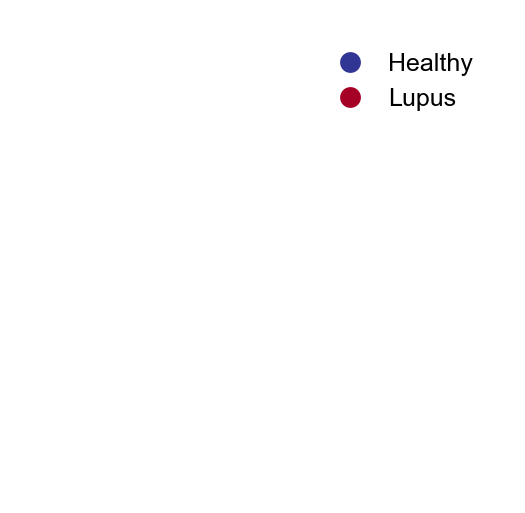

In [70]:
legend_elements = [
    Line2D([0], [0], marker='o', markerfacecolor=plt.get_cmap('RdYlBu')(0.999), color='w', label='Healthy', markersize=6),
    Line2D([0], [0], marker='o', markerfacecolor=plt.get_cmap('RdYlBu')(0), color='w', label='Lupus', markersize=6),
]

plt.figure(figsize=(2, 2), dpi=300)
plt.legend(
    handles=legend_elements, 
    ncols=1, 
    loc='upper right', 
    fontsize=6, 
    frameon=False,
    labelspacing=0.5,
    handletextpad=0.5,
    columnspacing=0.5,
)
plt.axis('off')
plt.show()


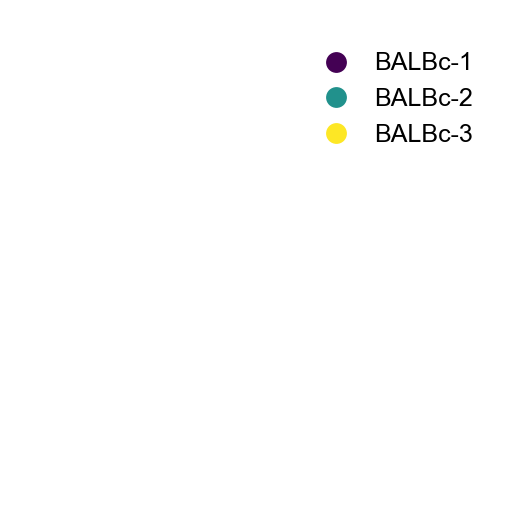

In [71]:
legend_elements = [
    Line2D([0], [0], marker='o', markerfacecolor=plt.get_cmap('viridis')(0), color='w', label='BALBc-1', markersize=6),
    Line2D([0], [0], marker='o', markerfacecolor=plt.get_cmap('viridis')(0.5), color='w', label='BALBc-2', markersize=6),
    Line2D([0], [0], marker='o', markerfacecolor=plt.get_cmap('viridis')(0.999), color='w', label='BALBc-3', markersize=6),
]

plt.figure(figsize=(2, 2), dpi=300)
plt.legend(
    handles=legend_elements, 
    ncols=1, 
    loc='upper right', 
    fontsize=6, 
    frameon=False,
    labelspacing=0.5,
    handletextpad=0.5,
    columnspacing=0.5,
)
plt.axis('off')
plt.show()


## Colorbars

/tmp/ipykernel_2946542/1087159002.py:15: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)


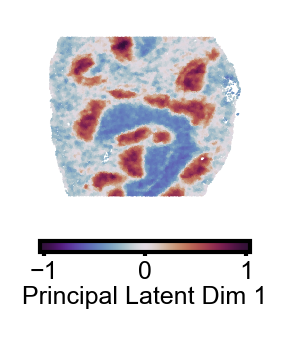

In [72]:
plt.figure(figsize=(0.9, 1.1), dpi=300)
plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=balbc3_decomposed[:, 1],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_1_lim,
    vmax=pd_1_lim,
    cmap='twilight_shifted',
)
plt.axis('off')
cbar = plt.colorbar(orientation='horizontal')
cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)
cbar.ax.xaxis.set_tick_params(size=1, pad=1)
cbar.set_label('Principal Latent Dim 1', labelpad=0.5)

/tmp/ipykernel_2946542/1720124762.py:15: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)


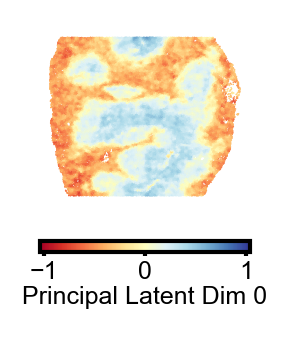

In [73]:
plt.figure(figsize=(0.9, 1.1), dpi=300)
plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=balbc3_decomposed[:, 0],
    s=0.03,
    linewidths=0.2,
    alpha=1,
    vmin=-pd_1_lim,
    vmax=pd_1_lim,
    cmap='RdYlBu',
)
plt.axis('off')
cbar = plt.colorbar(orientation='horizontal')
cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)
cbar.ax.xaxis.set_tick_params(size=1, pad=1)
cbar.set_label('Principal Latent Dim 0', labelpad=0.5)

## Mouse Level Analysis

In [268]:
DUMMY_COL_NAME = 1

cell_df = bag_cello_df.cell_df

cell_df[DUMMY_COL_NAME] = 1

In [396]:
PREDICTION_CLUSTER_COLUMN = 'Cellohood Neighborhood Cluster'
PREDICTION_75_CLUSTER_COLUMN = 'Cellohood Neighborhood Cluster 75'
CC_CLUSTER_NAME = 'cellohood_neighborhood_cluster'
CELLTYPE_COLNAME = 'CellType'
CELLTYPE_PLOT_NAME = 'Cell Type'

NB_OF_CLUSTERS = 14

In [397]:
cellohood.summarize_latent_direction_result(latent_direction_result)

Latent Direction Summary:
Variance: 0.5 (dim=3), selected clusters = [11, 16, 24].
Variance: 0.75 (dim=12), selected clusters = [18].
Variance: 1.0 (dim=64), selected clusters = [11, 14, 18, 21, 26].


In [398]:
predictions = cellohood.get_latent_directions_predictions(
            latent_direction_result=latent_direction_result,
            explained_variance=1.0,
            selected_number_of_clusters=NB_OF_CLUSTERS,
        )

predictions_75 = cellohood.get_latent_directions_predictions(
            latent_direction_result=latent_direction_result,
            explained_variance=0.75,
            selected_number_of_clusters=18,
        )

In [399]:
from collections import Counter

len(Counter(predictions))

14

In [400]:
bag_cello_df.cell_df[PREDICTION_CLUSTER_COLUMN] = bag_cello_df.cell_df[CC_CLUSTER_NAME].apply(
    lambda x: predictions[x])
bag_cello_df.cell_df[PREDICTION_75_CLUSTER_COLUMN] = bag_cello_df.cell_df[CC_CLUSTER_NAME].apply(
    lambda x: predictions_75[x])

In [401]:
#PREDICTION_CLUSTER_COLUMN = PREDICTION_75_CLUSTER_COLUMN

In [402]:
celltype_counts = pandas.pivot_table(
    bag_cello_df.cell_df, 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CELLTYPE_COLNAME],
    aggfunc="sum",
).fillna(0)

In [403]:
celltype_counts.shape

(14, 27)

In [404]:
celltype_percentages = (celltype_counts.T / celltype_counts.sum(axis=1)).T
celltype_percentages.columns.name = CELLTYPE_PLOT_NAME

In [405]:
PLOTTING_DPI = 300

In [406]:
celltypes = list(celltype_percentages.columns)

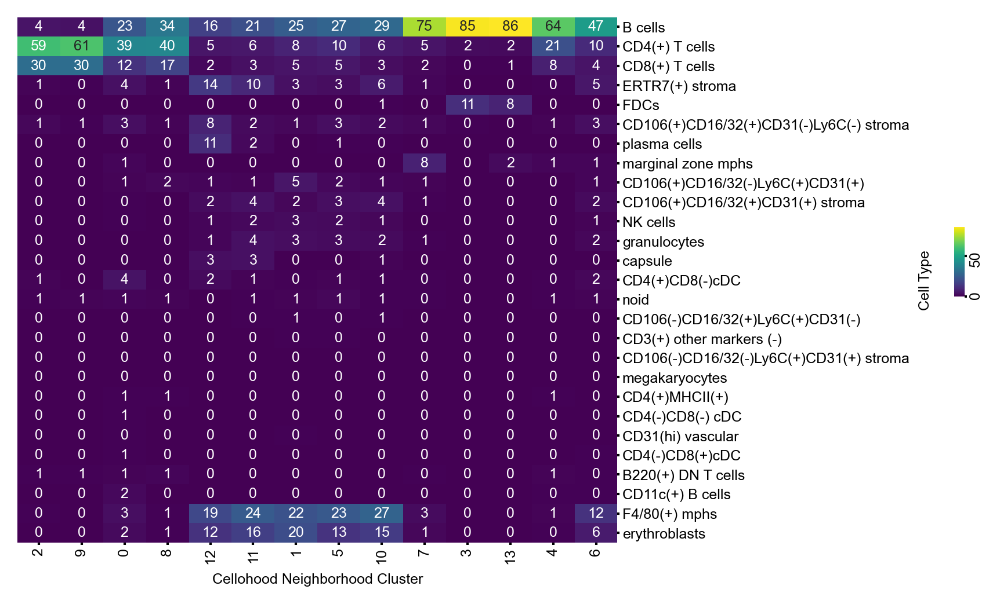

In [407]:
import seaborn as sns

celltype_clustermap = sns.clustermap(
    celltype_percentages[celltypes].T * 100, 
    annot=True,
    #row_colors=celltypes_color_df,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.05, 0.4, 0.01, 0.1),
    annot_kws={"size": 6},
    cbar_kws={'label': ''}
)

#celltype_clustermap.ax_cbar.set_xlabel(f'{CELLTYPE_PLOT_NAME} percentage', labelpad=0, size=6)

celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1, rotation=90)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(celltype_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
#celltype_clustermap.ax_row_colors.set_xticklabels(celltype_clustermap.ax_row_colors.get_xticklabels(), size=6)
#celltype_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, pad=1)

celltype_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_clustermap.fig.set_size_inches((6, 4))

## Marker analysis

### Cell type level:
For each marker compute the average marker expression for a given cell type:

In [408]:
marker_to_celltype_dfs = {}

MARKERS_CLEAN = MARKER_COL_NAMES
MARKER_PLOT_NAME = 'Markers'
ALL_PLOT_NAME = 'All'


for marker in MARKER_COL_NAMES:
    marker_to_celltype_dfs[marker] = pandas.pivot_table(
    cell_df, 
    values=marker, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CELLTYPE_COLNAME],
    aggfunc='mean',
).fillna(0)

Now - let us transpose this dictionary to cell type to marker df:

In [409]:
import numpy

marker_ct_ipc = numpy.stack([
    marker_df.values
    for marker_df in marker_to_celltype_dfs.values()
])

celltype_to_marker_dfs = {
    ct: pandas.DataFrame(
        marker_ct_ipc[:, :, ct_ind],
        index=MARKER_COL_NAMES,
    )
    for ct_ind, ct in enumerate(celltypes)
}

Now - let's rename the markers to their clean names:

In [410]:
celltype_to_marker_dfs_clean = {}


for celltype, cdf in celltype_to_marker_dfs.items():
    cdf_clean = cdf.copy()
    cdf_clean[MARKER_PLOT_NAME] = MARKERS_CLEAN
    cdf_clean.set_index(MARKER_PLOT_NAME, inplace=True),
    celltype_to_marker_dfs_clean[celltype] = cdf_clean

## All marker analysis:

Now let's compute the overall marker distribution across all cells:

In [411]:
all_markers_distribution = bag_cello_df.cell_df.groupby([PREDICTION_CLUSTER_COLUMN]).mean()[MARKER_COL_NAMES]
all_markers_distribution -= all_markers_distribution.mean()
all_markers_distribution /= all_markers_distribution.std()
all_markers_distribution.columns = MARKER_COL_NAMES


celltype_to_marker_dfs_clean[ALL_PLOT_NAME] = all_markers_distribution.T

/tmp/ipykernel_2946542/3658460709.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  all_markers_distribution = bag_cello_df.cell_df.groupby([PREDICTION_CLUSTER_COLUMN]).mean()[MARKER_COL_NAMES]


Now let's display the all marker distributions:

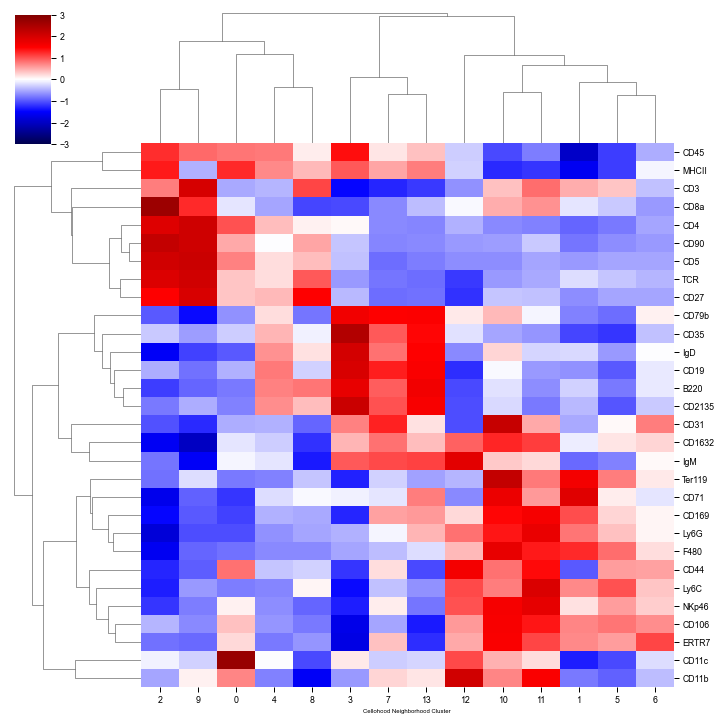

In [412]:
sns.clustermap(all_markers_distribution.T, center=0, cmap='seismic', vmin=-3, vmax=3, yticklabels=True)

Now - let's visualize the Cellohood Neighobrhoods with average markers.

Let's start with providing some handy tools:
- marker colormap:

In [413]:
import matplotlib

marker_color_norm = matplotlib.colors.Normalize(vmin=-2, vmax=2)
marker_cmap = plt.get_cmap('coolwarm')

marker_sm = matplotlib.cm.ScalarMappable(norm=marker_color_norm, cmap=marker_cmap)

and a code to transform values to vectors:


In [414]:
def transform_vec_to_colors(
    vec,
    colors,
    standarize=True,
    display=None,
    permute=None,
    ignore_color=(160 / 255, 160 / 255, 160 / 255),
):
    if standarize:
        display = display if display is not None else numpy.arange(len(vec))
        vec = vec.copy()
        vec = vec - numpy.mean(vec[display])
        vec = vec / numpy.std(vec[display])
    result = [
        colors.to_rgba(x)
        for x in vec
    ]
    if display is not None:
        new_result = []
        for ind_, result_col in enumerate(result):
            current_color = list(result_col)
            if ind_ in display:
                pass 
            else:
                current_color = ignore_color
            new_result.append(current_color)
            
        result = new_result
    if permute:
        result = [
            result[i]
            for i in permute
        ]
    return result

In [415]:
all_colors_dict = {
    f'{marker}': transform_vec_to_colors( 
        vec=celltype_to_marker_dfs_clean[ALL_PLOT_NAME].loc[marker],
        colors=marker_sm,
    )
    for marker in MARKERS_CLEAN
}

all_colors_df = pandas.DataFrame(all_colors_dict)

and visualize CC clusters with average marker distributions:


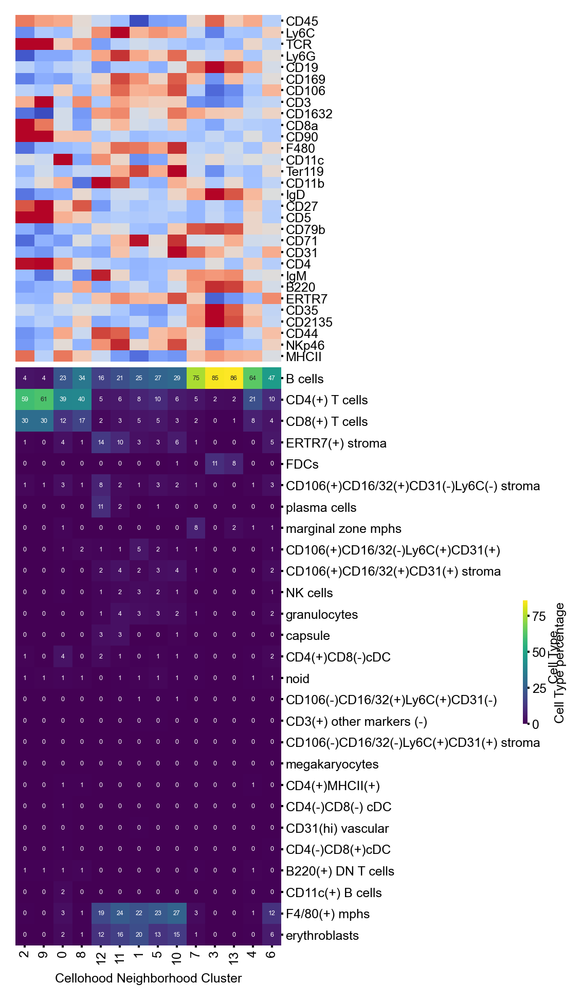

In [416]:
celltype_with_all_markers_clustermap = sns.clustermap(
    celltype_percentages[celltypes].T * 100, 
    annot=True,
    #row_colors=celltypes_color_df,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.25, 0.225, 0.01, 0.1),
    col_colors=all_colors_df,
    annot_kws={'size': 3},
    yticklabels=1,
    colors_ratio=(0.01, 0.01),
    cbar_kws={'label': f'{CELLTYPE_PLOT_NAME} percentage'}
)

celltype_with_all_markers_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_with_all_markers_clustermap.ax_row_dendrogram.set_visible(False)
celltype_with_all_markers_clustermap.ax_col_dendrogram.set_visible(False)

celltype_with_all_markers_clustermap.ax_heatmap.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_with_all_markers_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_with_all_markers_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_with_all_markers_clustermap.ax_heatmap.set_xticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)

#celltype_with_all_markers_clustermap.ax_row_colors.set_xticklabels(
#    celltype_with_all_markers_clustermap.ax_row_colors.get_xticklabels(), size=6
#)
celltype_with_all_markers_clustermap.ax_col_colors.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_col_colors.get_yticklabels(), size=6
)
celltype_with_all_markers_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

celltype_with_all_markers_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_with_all_markers_clustermap.fig.set_size_inches((3, 8))

In [417]:
roi_counts = pandas.pivot_table(
    cell_df, 
    values=DUMMY_COL_NAME, 
    index=['sample'],
    columns=[PREDICTION_CLUSTER_COLUMN],
    aggfunc="sum",
).fillna(0)

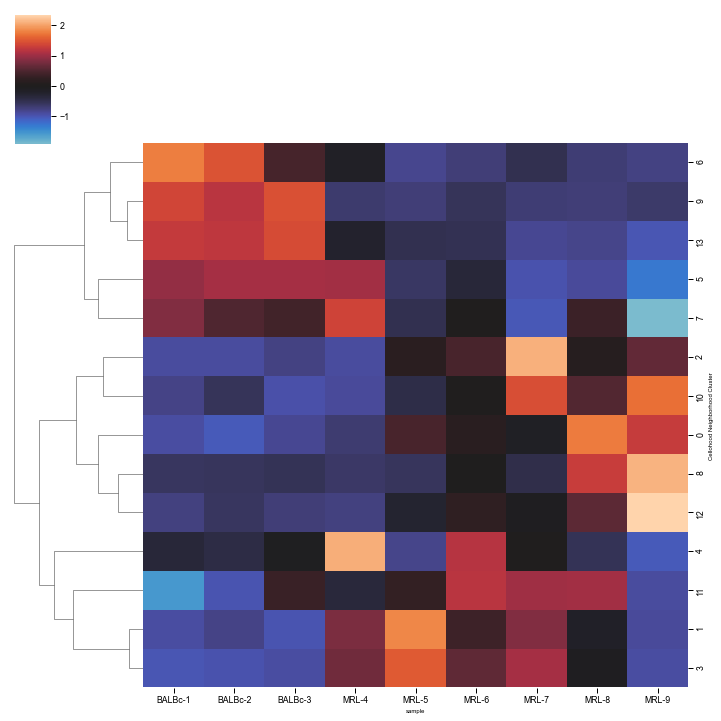

In [418]:
sns.clustermap(
    roi_counts.T,
    col_cluster=False,
    z_score=0,
    center=0,
)

In [419]:
cc_densities = cell_df.groupby(
    [PREDICTION_CLUSTER_COLUMN, CC_CLUSTER_NAME]
).size().groupby(PREDICTION_CLUSTER_COLUMN).mean()

In [1170]:
# celltypes_to_marker_to_show = {
#     'erythroblasts': ['CD71', 'Ter119', 'CD27'],
#     'F4/80(+) mphs': ['CD11c'],
#     'CD4(+) T cells': ['CD45', 'CD44', 'MHCII', 'CD90', 'CD27'],
#     'CD8(+) T cells': ['CD45', 'CD44', 'MHCII', 'CD90'],
#     'B cells': ['IgD', 'B220', 'CD45', 'CD79b', 'CD5'],
#     'All': ['Ly6C', 'Ly6G', 'IgM', 'ERTR7']
# }

celltypes_to_marker_to_show = {
    'erythroblasts': ['CD71', 'Ter119', 'CD27'],
    'F4/80(+) mphs': ['CD11c', 'CD169'],
    'CD4(+) T cells': ['CD45', 'CD44', 'MHCII', 'CD90', 'CD27'],
    'CD8(+) T cells': ['CD45', 'CD44', 'MHCII', 'CD90'],
    'B cells': ['IgD', 'B220', 'CD45', 'CD79b', 'CD5', 'CD2135', 'MHCII'],
    'All': ['Ly6C', 'Ly6G', 'IgM', 'ERTR7']
}

In [1171]:
from collections import defaultdict

celltypes_display_percentage = defaultdict(lambda: 0.1)

In [1172]:
celltypes_cc_display = {
    ct: [
        ind_ 
        for ind_, cc_ in enumerate(celltype_percentages[ct] > celltypes_display_percentage[ct])
        if cc_
    ]
    for ct in celltypes_to_marker_to_show
    if ct in celltype_percentages.columns
}

In [1173]:
[len(val) for key, val in cc_colors_dict.items()]

[14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14,
 14]

In [1174]:
cc_colors_dict = {}
for ct, markers in celltypes_to_marker_to_show.items():
    for marker in markers:
        print(celltype_to_marker_dfs_clean[ct].loc[marker].shape)
        cc_colors_dict[f'{ct}: {marker}'] = transform_vec_to_colors( 
                vec=celltype_to_marker_dfs_clean[ct].loc[marker],
                colors=marker_sm,
                display=celltypes_cc_display[ct] if ct in celltypes_cc_display else None,
            )


cc_marker_ct_colors = pandas.DataFrame(cc_colors_dict)

cc_marker_ct_colors['All: Cell density'] = transform_vec_to_colors( 
        vec=cc_densities,
        colors=marker_sm,
)

(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)
(14,)


/tmp/ipykernel_2946542/3859148886.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_2946542/3859148886.py:68: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


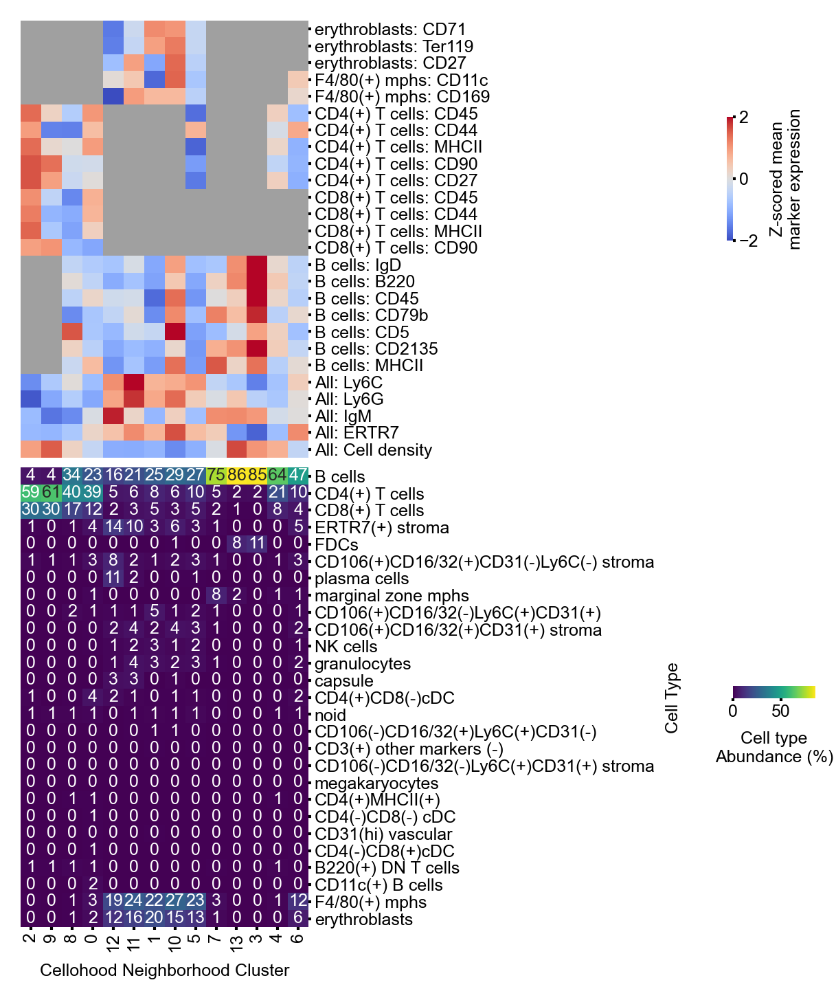

In [1175]:
COLORBARS_SHIFT = 0.92

cc_abundance_std_argsort = (-celltype_percentages['B cells'].values).argsort()

celltype_clustermap = sns.clustermap(
    (celltype_percentages[celltypes].T * 100)[cc_abundance_std_argsort], 
    annot=True,
    col_cluster=True,
    fmt='.0f',
    cmap='viridis',
    figsize=(5, 7),
    col_colors=cc_marker_ct_colors,
    #row_colors=[class_to_color[celltype_to_class[ct]] for ct in numpy.array(celltypes)],
    colors_ratio=0.015,
    yticklabels=True,
    xticklabels=cc_abundance_std_argsort,
    #linewidth=0.003
    #annot_kws={"size": 3},
    cbar_pos=[COLORBARS_SHIFT + 0.05, 0.25, 0.1, .01],
    cbar_kws={'label': 'Cell type\nAbundance (%)', 'orientation': 'horizontal'}
)


#handles = [Patch(facecolor=class_to_color[name]) for name in class_to_color]
#plt.legend(
#    handles, 
#    class_to_color, 
#    title=' Cell type Metatype',
#    bbox_to_anchor=(0.17, 0.53), 
#    bbox_transform=plt.gcf().transFigure,
#    frameon=False,
#    fontsize=6,
#)

celltype_clustermap.ax_col_dendrogram.set_visible(False)

cb_ax = celltype_clustermap.fig.add_axes([COLORBARS_SHIFT, .27, .05, .8])
cb_ax.imshow([[0, 1]])
cb_ax.set_visible(False)

cbar = celltype_clustermap.fig.colorbar(
    marker_sm, 
    drawedges=False,
    #bbox_to_anchor=(1, 0.5),
    label='Z-scored mean\nmarker expression',
    ax=cb_ax,
    #panchor=(1.5, 0.5),
    #anchor=(1.5, 0.5),
)

cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=6, size=1, pad=1)

celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(celltype_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
celltype_clustermap.ax_col_colors.set_yticklabels(celltype_clustermap.ax_col_colors.get_yticklabels(), size=6)
celltype_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)


celltype_clustermap.fig.set_dpi(300)
celltype_clustermap.fig.set_size_inches((4, 6))
plt.tight_layout()

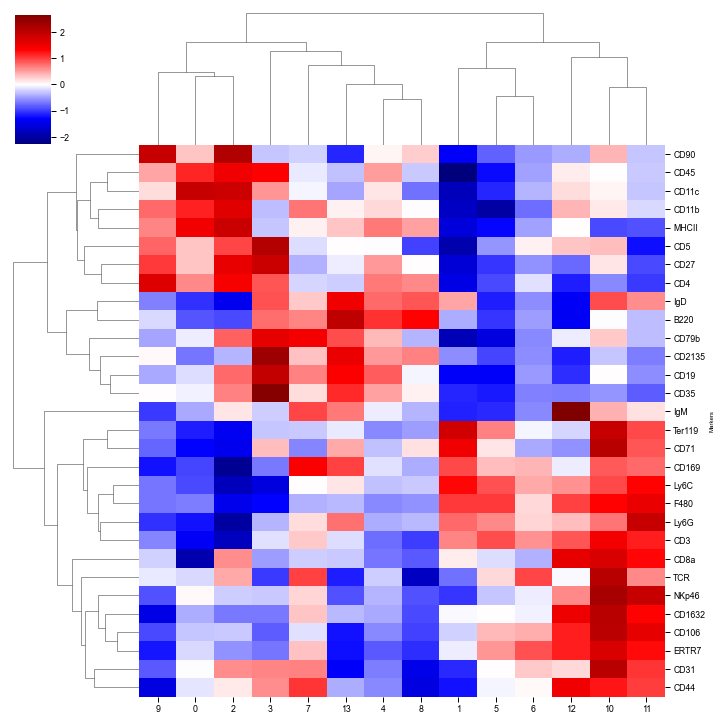

In [1176]:
sns.clustermap(
    celltype_to_marker_dfs_clean['CD4(+) T cells'], 
    z_score=0, 
    col_cluster=True,
    cmap='seismic',
    center=0,
)

In [1177]:
cell_df['cellohood_neighborhood_cluster']

0              0
1              0
2              0
3              0
4              0
           ...  
734098    136501
734099    136501
734100    136501
734101    136501
734102    136501
Name: cellohood_neighborhood_cluster, Length: 734103, dtype: int64

In [1178]:
# CLUSTERS_TO_COMPARE = [1, 10]

# for marker in celltype_to_marker_dfs_clean['erythroblasts'].index:
#     for cl in CLUSTERS_TO_COMPARE:
#         plt.hist(cell_df[cell_df[PREDICTION_CLUSTER_COLUMN] == cl][marker], label=cl, density=True, alpha=0.5, bins=50)
#     plt.legend()
#     plt.title(marker)
#     plt.show()

In [1179]:
celltype_to_marker_dfs_clean['erythroblasts'].index

Index(['CD45', 'Ly6C', 'TCR', 'Ly6G', 'CD19', 'CD169', 'CD106', 'CD3',
       'CD1632', 'CD8a', 'CD90', 'F480', 'CD11c', 'Ter119', 'CD11b', 'IgD',
       'CD27', 'CD5', 'CD79b', 'CD71', 'CD31', 'CD4', 'IgM', 'B220', 'ERTR7',
       'CD35', 'CD2135', 'CD44', 'NKp46', 'MHCII'],
      dtype='object', name='Markers')

In [1180]:
ct_norm = matplotlib.colors.Normalize(vmin=0, vmax=celltype_percentages.values.max())
ct_cmap = plt.get_cmap('viridis')

ct_sm = matplotlib.cm.ScalarMappable(norm=ct_norm, cmap=ct_cmap)

In [1181]:
max_table = celltype_clustermap.data2d.max(axis=1)

In [1200]:
CT_PERCENTAGE_THRESHOLD = 5

full_cc_colors_with_ct = cc_marker_ct_colors.copy()

for celltype in celltype_clustermap.data2d.index:
    if max_table[celltype] < CT_PERCENTAGE_THRESHOLD:
        continue
    full_cc_colors_with_ct[f'{celltype}'] = [
        ct_sm.to_rgba(x) for x in celltype_percentages[celltype]
    ]

In [1201]:
healthy_argsort = numpy.argsort(
    (roi_counts.T * (numpy.arange(1, 9 + 1) ** 2)
).sum(axis=1) / roi_counts.T.sum(axis=1))

In [1202]:
roi_counts.columns.name = ''

In [1203]:
from matplotlib import colors as mcolors

CLUSTER_TO_COLOR = defaultdict(lambda: mcolors.CSS4_COLORS['gray'])
CLUSTER_TO_COLOR[9] = mcolors.CSS4_COLORS['blue']
CLUSTER_TO_COLOR[13] = mcolors.CSS4_COLORS['black']
CLUSTER_TO_COLOR[11] = mcolors.CSS4_COLORS['orangered']
CLUSTER_TO_COLOR[4] = mcolors.CSS4_COLORS['purple']
CLUSTER_TO_COLOR[0] = mcolors.CSS4_COLORS['darkslateblue']
CLUSTER_TO_COLOR[3] = mcolors.CSS4_COLORS['dodgerblue']
CLUSTER_TO_COLOR[12] = mcolors.CSS4_COLORS['deeppink']
CLUSTER_TO_COLOR[6] = mcolors.CSS4_COLORS['yellow']
CLUSTER_TO_COLOR[5] = mcolors.CSS4_COLORS['red']
CLUSTER_TO_COLOR[7] = mcolors.CSS4_COLORS['gray']
CLUSTER_TO_COLOR[8] = mcolors.CSS4_COLORS['olive']
CLUSTER_TO_COLOR[2] = mcolors.CSS4_COLORS['cyan']
CLUSTER_TO_COLOR[1] = mcolors.CSS4_COLORS['hotpink']
CLUSTER_TO_COLOR[10] = mcolors.CSS4_COLORS['magenta']


#full_cc_colors_with_ct['Cluster Color'] = [CLUSTER_TO_COLOR[i] for i in range(NB_OF_CLUSTERS)]

In [1204]:
celltype_clustermap.data2d.columns

Int64Index([2, 9, 8, 0, 12, 11, 1, 10, 5, 7, 13, 3, 4, 6], dtype='int64', name='Cellohood Neighborhood Cluster')

In [1205]:
CLUSTER_ORDER = [
   # 4, 10, 0, 1, 12, 2, 5, 3, 6, 9, 8, 11, 13, 14, 7
    9, 2, 0, 8, 12, 11, 1, 10, 5, 7, 13, 3, 4, 6
]

for i in range(NB_OF_CLUSTERS):
    if i not in CLUSTER_ORDER:
        CLUSTER_ORDER.append(i)

In [1206]:
EXCHANGE_LONG_NAMES = {
    'CD106(+)CD16/32(+)CD31(-)Ly6C(-) stroma': '*',
    'CD106(+)CD16/32(-)Ly6C(+)CD31(+)': '**',
}

In [1207]:
full_cc_colors_with_ct.columns = [
    EXCHANGE_LONG_NAMES[col] if col in EXCHANGE_LONG_NAMES else col
    for col in full_cc_colors_with_ct.columns
]

In [1208]:
STATE_TO_COLOR = {
    'Healthy': mcolors.CSS4_COLORS['forestgreen'],
    'Early': mcolors.CSS4_COLORS['bisque'],
    'Intermediate': mcolors.CSS4_COLORS['darkorange'],
    'Late': mcolors.CSS4_COLORS['maroon'],
}

In [1209]:
sample_colors = pandas.DataFrame(
    [
        STATE_TO_COLOR['Healthy']
    ] * 3 + [
        STATE_TO_COLOR['Early']
    ] * 3 + [
        STATE_TO_COLOR['Intermediate']
    ] * 2 + [STATE_TO_COLOR['Late']],
    index=roi_counts.index,
    #columns=['Lupus Status']
)

In [1210]:
roi_counts.index.name = 'Sample'
roi_counts.columns.name = 'Cellular Neighborhood'

In [1211]:
LUPUS_ORDER = numpy.argsort(((roi_counts / roi_counts.sum(axis=0)).T * numpy.arange(9)).sum(axis=1))

In [1212]:
full_cc_colors_with_ct.insert(loc=26, value=[(1, 1, 1, 1)] * len(full_cc_colors_with_ct), column='')

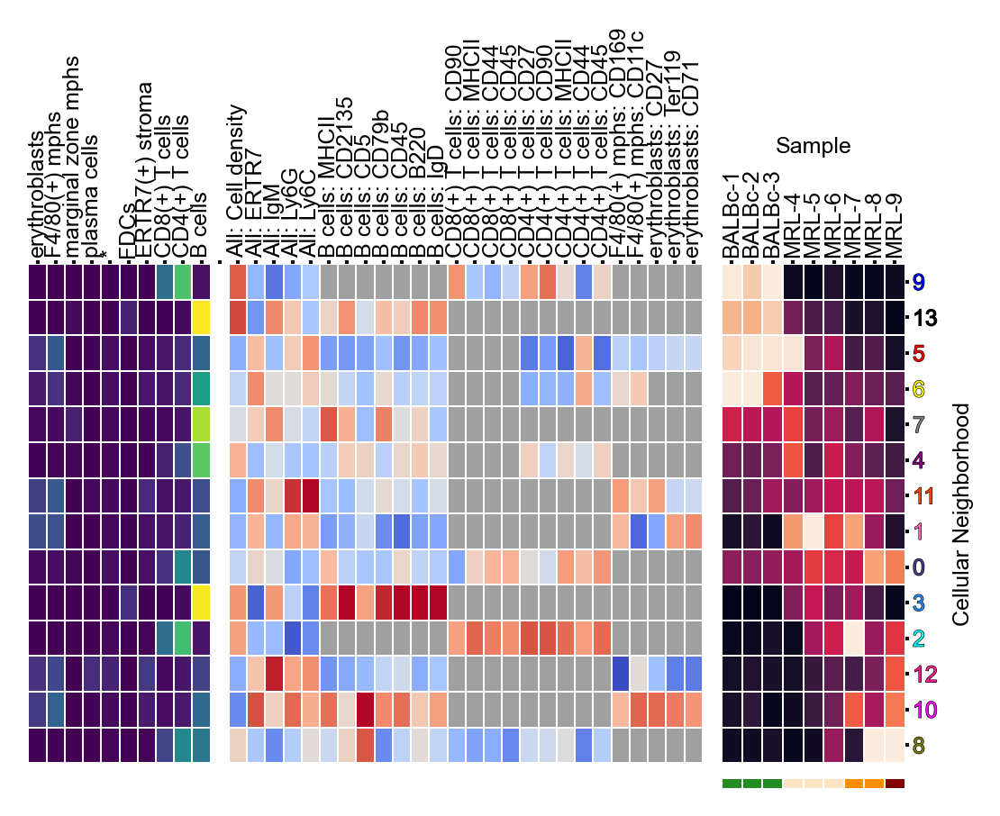

In [1213]:
from matplotlib import patheffects


big_l_figure = sns.clustermap(
    roi_counts.T.iloc[LUPUS_ORDER],
    col_cluster=False,
    row_cluster=False,
    row_colors=full_cc_colors_with_ct.iloc[:, ::-1],
    col_colors = sample_colors,
    colors_ratio=0.017,
    cbar_pos=[0.57, 0.73, 0.05, 0.007],
    cbar_kws={'label': 'CN abundance', 'aspect': 10, 'orientation': 'horizontal'},
    xticklabels=True,
    vmax=numpy.quantile(roi_counts.values.flatten(), 0.95),
    linewidth=0.001,
)

big_l_figure.fig.set_size_inches((4.2, 2.8))
big_l_figure.fig.set_dpi(PLOTTING_DPI)

big_l_figure.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
big_l_figure.ax_heatmap.set_yticklabels(
    big_l_figure.ax_heatmap.get_yticklabels(), size=6,
)
big_l_figure.ax_col_colors.set_yticks([])
big_l_figure.ax_heatmap.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_heatmap.set_xticklabels(
    big_l_figure.ax_heatmap.get_xticklabels(), size=6,
)
big_l_figure.ax_heatmap.xaxis.tick_top()
big_l_figure.ax_heatmap.yaxis.tick_left()

big_l_figure.ax_row_colors.xaxis.set_tick_params(size=1, pad=1, rotation=90)
big_l_figure.ax_row_colors.set_xticklabels(
    big_l_figure.ax_row_colors.get_xticklabels(), size=6,
)
big_l_figure.ax_row_colors.xaxis.tick_top()
big_l_figure.ax_cbar.set_visible(False)

ax_row_colors = big_l_figure.ax_row_colors
row_box = ax_row_colors.get_position()
big_l_figure.ax_col_dendrogram.set_visible(False)
big_l_figure.ax_row_dendrogram.set_visible(False)

ax_row_colors = big_l_figure.ax_row_colors
ax_col_colors = big_l_figure.ax_col_colors
row_box = ax_row_colors.get_position()
col_box = ax_col_colors.get_position()

big_l_figure.ax_heatmap.yaxis.tick_right()


for ytick in big_l_figure.ax_heatmap.get_yticklabels():
    label_text = ytick.get_text()
    if int(label_text) in CLUSTER_TO_COLOR:
        ytick.set_color(CLUSTER_TO_COLOR[int(label_text)])
        ytick.set_path_effects([
            patheffects.Stroke(linewidth=0.3, foreground='black'),
            patheffects.Normal()
        ])
        #ytick.set_bbox(dict(boxstyle="round,pad=0.3", facecolor='lightgray', alpha=0.7))
        
big_l_figure.ax_heatmap.xaxis.set_label_position('top') 

box_heatmap = big_l_figure.ax_heatmap.get_position()
ax_col_colors.set_position([col_box.x0, box_heatmap.min[1] - col_box.height - 0.02, col_box.width, col_box.height])
ax_row_colors.set_position([box_heatmap.x0 - 0.017 - row_box.width, row_box.y0, row_box.width, row_box.height])

(-0.05500000000000001,
 0.05500000000000001,
 -0.05500000000000001,
 0.05500000000000001)

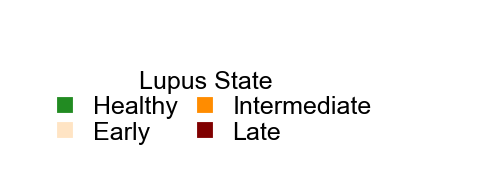

In [1164]:
from matplotlib.pyplot import Line2D

plt.figure(figsize=(1, 0.5), dpi=300)

plt.plot([0], [0])

state_colors = list(STATE_TO_COLOR.values())

state_elements = [
    Line2D([0], [0], marker='s', markerfacecolor=state_colors[0], color='w', label='Healthy', markersize=5),
    Line2D([0], [0], marker='s', markerfacecolor=state_colors[1], color='w', label='Early', markersize=5),
    Line2D([0], [0], marker='s', markerfacecolor=state_colors[2], color='w', label='Intermediate', markersize=5),
    Line2D([0], [0], marker='s', markerfacecolor=state_colors[3], color='w', label='Late', markersize=5),
]

plt.legend(
    handles=state_elements, 
    ncols=2, 
    loc=(-0.8, -0.1), 
    fontsize=6, 
    frameon=False,
    title='Lupus State',
    title_fontsize=6,
    labelspacing=0.1,
    columnspacing=0.1,
    handletextpad=0.1,
)
plt.axis('off')

In [1165]:
ami(
    cell_df[PREDICTION_CLUSTER_COLUMN][cell_df["Compartment"].apply(lambda x: x in compartments[:4])],
    cell_df["Compartment"][cell_df["Compartment"].apply(lambda x: x in compartments[:4])])

0.48337404976584303

In [1166]:
bag_df = cell_df.groupby('cellohood_neighborhood_cluster').first()

/tmp/ipykernel_2946542/608223783.py:6: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  plt.scatter(


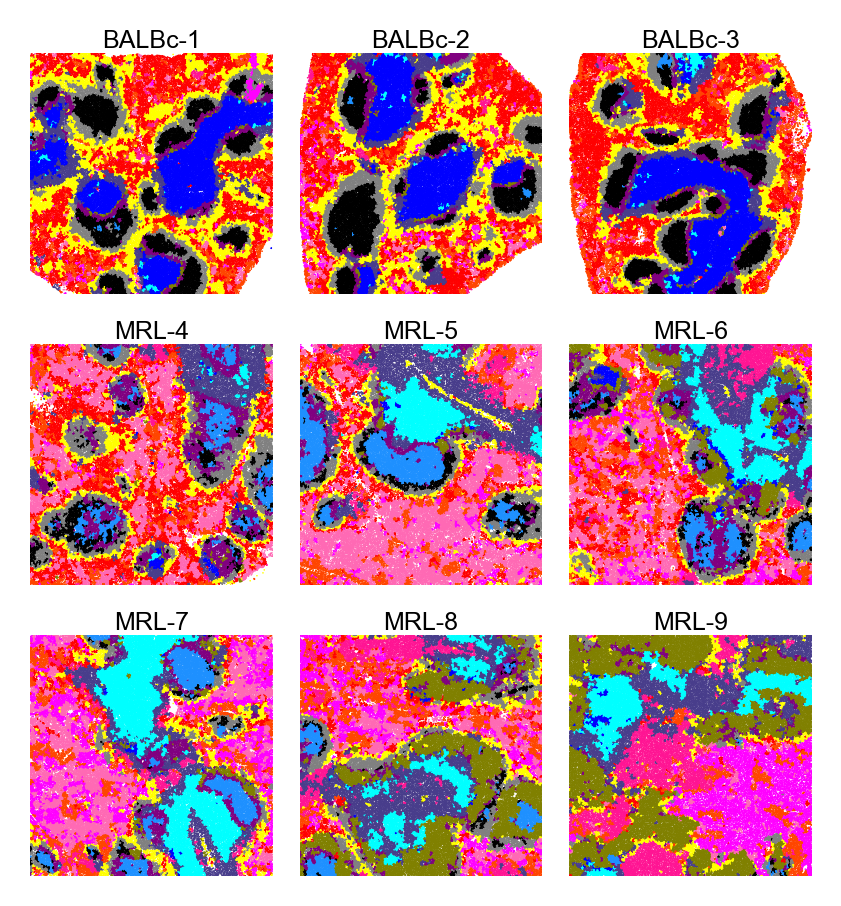

In [1167]:
plt.figure(figsize=(6.5 / 7 * 3, 3), dpi=300)

for sample_ind, sample in enumerate(sorted(set(cell_df['sample'])), start=1):
    plt.subplot(3, 3, sample_ind)
    sample_df = cell_df[cell_df['sample'] == sample]
    plt.scatter(
        sample_df['tile.X'],
        sample_df['tile.Y'],
        c=sample_df[PREDICTION_CLUSTER_COLUMN].apply(lambda x: CLUSTER_TO_COLOR[x]),
        #alpha=1,
        s=0.03,
        #vmin=-1.5,
        #vmax=1.5,
        #cmap='tab20',
        linewidths=0.2,
        vmax=20,
        vmin=0,
    )
    plt.title(sample, size=6, pad=1)
    plt.axis('off')
    ax = plt.gca()
    ax.spines[['top', 'left']].set_visible(False)
    ax.spines[['bottom', 'right']].set_visible(False)
    _ = ax.set_xticks([])
    _ = ax.set_yticks([])
    ax.set_aspect('auto')
    ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
    ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])
plt.tight_layout()
#plt.subplots_adjust(wspace=0.35)

(-0.05500000000000001,
 0.05500000000000001,
 -0.05500000000000001,
 0.05500000000000001)

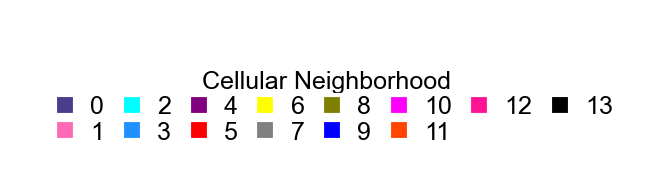

In [1168]:
plt.figure(figsize=(1, 0.5), dpi=300)

plt.plot([0], [0])

state_colors = list(STATE_TO_COLOR.values())

state_elements = [
    Line2D([0], [0], marker='s', markerfacecolor=CLUSTER_TO_COLOR[cl], color='w', label=cl, markersize=5)
    for cl in sorted(CLUSTER_TO_COLOR)
]

plt.legend(
    handles=state_elements, 
    ncols=len(state_elements) / 2 + 1, 
    loc=(-0.8, -0.1), 
    fontsize=6, 
    frameon=False,
    title='Cellular Neighborhood',
    title_fontsize=6,
    labelspacing=0.1,
    columnspacing=0.1,
    handletextpad=0.01,
)
plt.axis('off')

In [1169]:
MARKERS_CLEAN

['CD45',
 'Ly6C',
 'TCR',
 'Ly6G',
 'CD19',
 'CD169',
 'CD106',
 'CD3',
 'CD1632',
 'CD8a',
 'CD90',
 'F480',
 'CD11c',
 'Ter119',
 'CD11b',
 'IgD',
 'CD27',
 'CD5',
 'CD79b',
 'CD71',
 'CD31',
 'CD4',
 'IgM',
 'B220',
 'ERTR7',
 'CD35',
 'CD2135',
 'CD44',
 'NKp46',
 'MHCII']

In [864]:
PLD_75_CLUSTERS_TO_COLORS = {
    ind_: plt.get_cmap('tab20')(ind_) for ind_ in range(20)
}

PLD_75_CLUSTERS_TO_COLORS[3] = mcolors.CSS4_COLORS['blue']
PLD_75_CLUSTERS_TO_COLORS[0] = mcolors.CSS4_COLORS['purple']
PLD_75_CLUSTERS_TO_COLORS[5] = mcolors.CSS4_COLORS['black']
PLD_75_CLUSTERS_TO_COLORS[6] = mcolors.CSS4_COLORS['dimgray']
PLD_75_CLUSTERS_TO_COLORS[8] = mcolors.CSS4_COLORS['red']
PLD_75_CLUSTERS_TO_COLORS[4] = mcolors.CSS4_COLORS['gold']
PLD_75_CLUSTERS_TO_COLORS[7] = mcolors.CSS4_COLORS['lawngreen']
PLD_75_CLUSTERS_TO_COLORS[9] = mcolors.CSS4_COLORS['darkviolet']
PLD_75_CLUSTERS_TO_COLORS[1] = mcolors.CSS4_COLORS['lightcoral']
PLD_75_CLUSTERS_TO_COLORS[2] = mcolors.CSS4_COLORS['silver']

/tmp/ipykernel_2946542/857410101.py:6: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'vmin', 'vmax' will be ignored
  plt.scatter(


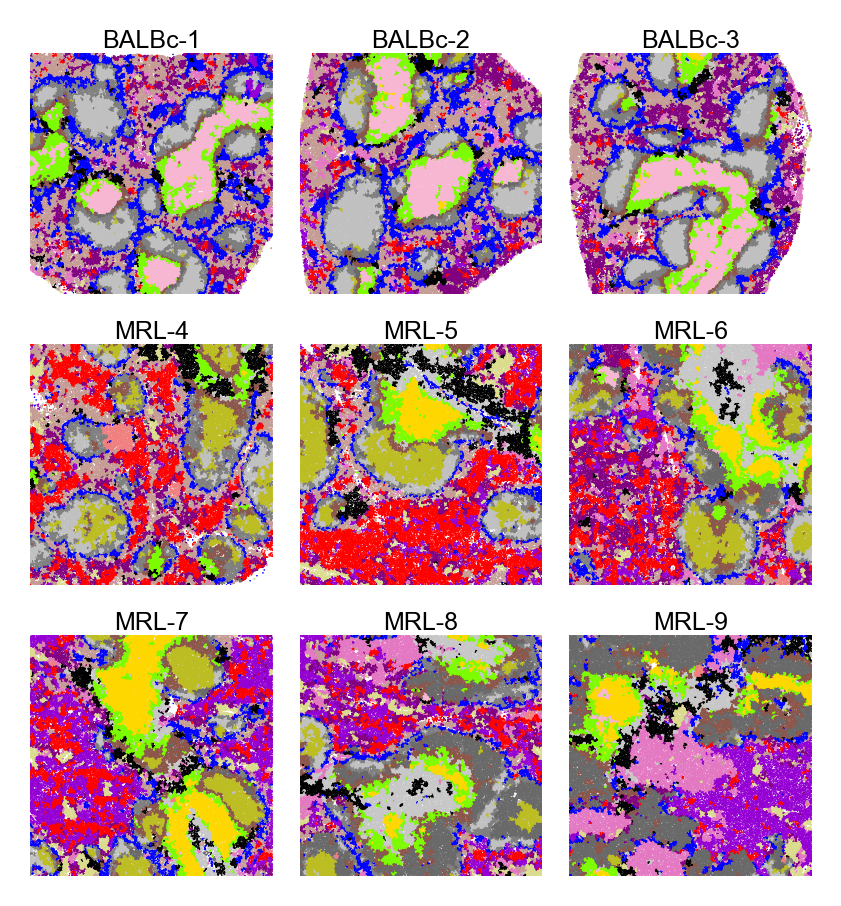

In [802]:
plt.figure(figsize=(6.5 / 7 * 3, 3), dpi=300)

for sample_ind, sample in enumerate(sorted(set(cell_df['sample'])), start=1):
    plt.subplot(3, 3, sample_ind)
    sample_df = cell_df[cell_df['sample'] == sample]
    plt.scatter(
        sample_df['tile.X'],
        sample_df['tile.Y'],
        c=sample_df[PREDICTION_75_CLUSTER_COLUMN].apply(lambda x: PLD_75_CLUSTERS_TO_COLORS[x]),
        #alpha=1,
        s=0.03,
        #vmin=-1.5,
        #vmax=1.5,
        cmap='tab20',
        linewidths=0.2,
        vmax=20,
        vmin=0,
    )
    plt.title(sample, size=6, pad=1)
    plt.axis('off')
    ax = plt.gca()
    ax.spines[['top', 'left']].set_visible(False)
    ax.spines[['bottom', 'right']].set_visible(False)
    _ = ax.set_xticks([])
    _ = ax.set_yticks([])
    ax.set_aspect('auto')
    ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
    ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])
plt.tight_layout()
#plt.subplots_adjust(wspace=0.35)

(-0.05500000000000001,
 0.05500000000000001,
 -0.05500000000000001,
 0.05500000000000001)

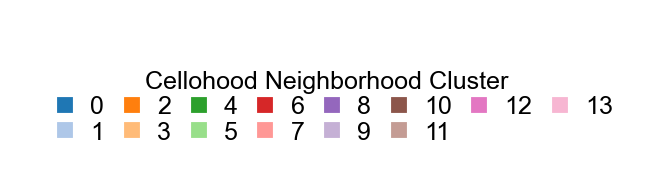

In [785]:
plt.figure(figsize=(1, 0.5), dpi=300)

plt.plot([0], [0])

state_colors = list(STATE_TO_COLOR.values())

state_elements = [
    Line2D([0], [0], marker='s', markerfacecolor=matplotlib.colormaps['tab20'](cl), color='w', label=cl, markersize=5)
    for cl in sorted(CLUSTER_TO_COLOR)
]

plt.legend(
    handles=state_elements, 
    ncols=len(state_elements) / 2 + 1, 
    loc=(-0.8, -0.1), 
    fontsize=6, 
    frameon=False,
    title='Cellohood Neighborhood',
    title_fontsize=6,
    labelspacing=0.1,
    columnspacing=0.1,
    handletextpad=0.01,
)
plt.axis('off')

Text(0.5, 1.0, 'Count')

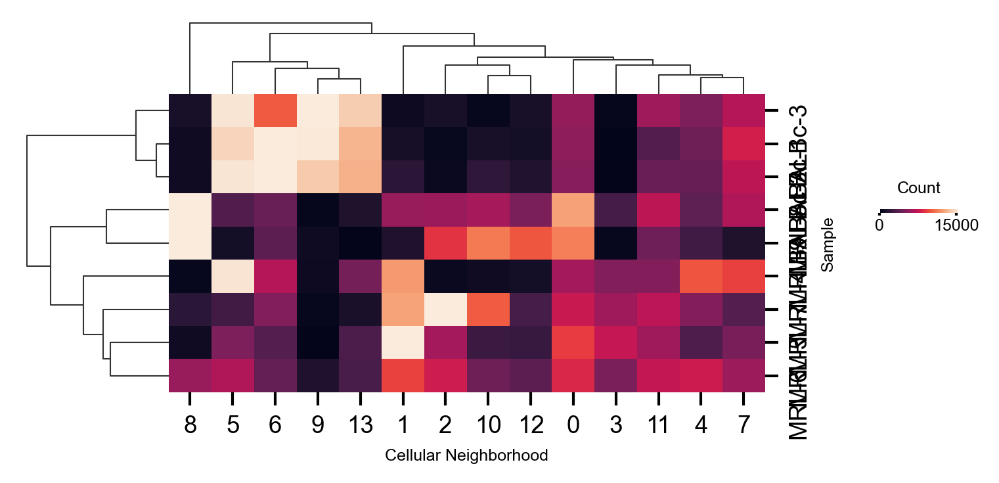

In [1012]:
count_cmap = sns.clustermap(
    roi_counts,
    vmax=numpy.quantile(roi_counts.values.flatten(), 0.95),
    cbar_pos=(1.1, 0.5, 0.1, 0.01),
    cbar_kws={'orientation': 'horizontal'}
)

count_cmap.fig.set_dpi(300)
count_cmap.fig.set_size_inches((4, 2))
count_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
count_cmap.ax_cbar.set_xticks([0, 15000])
count_cmap.ax_cbar.set_title('Count')

In [131]:
import os
os.getpid()

2946542

In [132]:
cocount = numpy.zeros((11, 12))


for l, r in zip(
    predictions[bag_df['sample'].apply(lambda x: not x.startswith('BALB'))], 
    predictions_75[bag_df['sample'].apply(lambda x: not x.startswith('BALB'))]):
    cocount[r, l] += 1

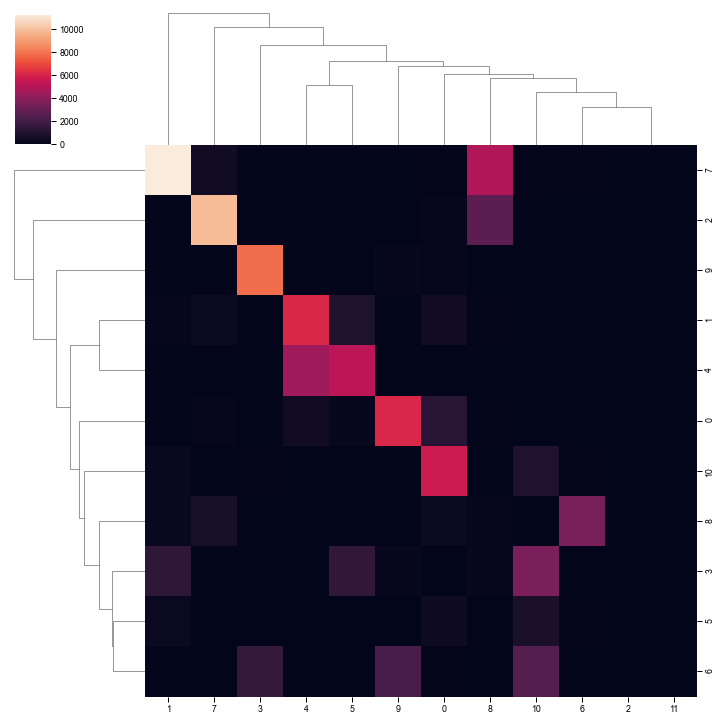

In [133]:
sns.clustermap(cocount)

(array([8.000e+00, 8.000e+00, 2.000e+01, 6.900e+01, 1.880e+02, 3.920e+02,
        6.890e+02, 1.524e+03, 2.377e+03, 3.472e+03, 4.705e+03, 5.473e+03,
        6.098e+03, 6.274e+03, 5.838e+03, 5.186e+03, 4.644e+03, 4.071e+03,
        3.610e+03, 3.199e+03, 3.074e+03, 3.187e+03, 3.303e+03, 3.405e+03,
        3.758e+03, 4.316e+03, 5.137e+03, 5.880e+03, 6.127e+03, 6.002e+03,
        5.487e+03, 5.446e+03, 4.958e+03, 4.439e+03, 3.791e+03, 2.978e+03,
        2.358e+03, 1.774e+03, 1.046e+03, 7.640e+02, 5.690e+02, 3.320e+02,
        2.670e+02, 1.420e+02, 6.800e+01, 2.700e+01, 1.100e+01, 7.000e+00,
        3.000e+00, 1.000e+00]),
 array([-0.17703944, -0.16922629, -0.16141315, -0.1536    , -0.14578685,
        -0.13797371, -0.13016056, -0.12234741, -0.11453427, -0.10672112,
        -0.09890797, -0.09109483, -0.08328168, -0.07546853, -0.06765539,
        -0.05984224, -0.05202909, -0.04421595, -0.0364028 , -0.02858965,
        -0.02077651, -0.01296336, -0.00515021,  0.00266293,  0.01047608,
         0.

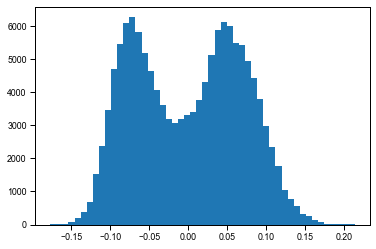

In [134]:
plt.hist(latent_direction_result.pca_sm_data[:, [0]], bins=50)

In [135]:
dim_0_ccs = ccs.cellohood_cluster_selection(
    x=latent_direction_result.pca_sm_data[:, [0]],
    clusters_to_analyze=list(range(1, 10)),
    take_every_example_for_training=10,
)
ccs.plot_ccs_result(dim_0_ccs)
plt.show()

 11%|██████████████████▊                                                                                                                                                      | 1/9 [00:48<06:27, 48.45s/it]


KeyboardInterrupt: 

In [ ]:
pld_0_predictions = dim_0_ccs.best_clusterers[3].predict(latent_direction_result.pca_sm_data[:, [0]])
PLD_0_PREDICTION_NAME = 'PLD_0'

In [ ]:
bag_cello_df.cell_df[PLD_0_PREDICTION_NAME] = bag_cello_df.cell_df[CC_CLUSTER_NAME].apply(
    lambda x: pld_0_predictions[x])

In [ ]:
PLD_0_COLORS = {
    0: mcolors.CSS4_COLORS['red'],
    1: mcolors.CSS4_COLORS['purple'],
    2: mcolors.CSS4_COLORS['yellow'],
}

In [ ]:
plt.figure(figsize=(6.5 / 7 * 3, 3), dpi=300)

for sample_ind, sample in enumerate(sorted(set(cell_df['sample'])), start=1):
    plt.subplot(3, 3, sample_ind)
    sample_df = cell_df[cell_df['sample'] == sample]
    plt.scatter(
        sample_df['tile.X'],
        sample_df['tile.Y'],
        c=sample_df[PLD_0_PREDICTION_NAME].apply(lambda x: PLD_0_COLORS[x]),
        #alpha=1,
        s=0.03,
        #vmin=-1.5,
        #vmax=1.5,
        cmap='seismic',
        linewidths=0.2,
        vmax=2,
        vmin=0,
    )
    plt.title(sample, size=6, pad=1)
    plt.axis('off')
    ax = plt.gca()
    ax.spines[['top', 'left']].set_visible(False)
    ax.spines[['bottom', 'right']].set_visible(False)
    _ = ax.set_xticks([])
    _ = ax.set_yticks([])
    ax.set_aspect('auto')
    ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
    ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])
plt.tight_layout()
#plt.subplots_adjust(wspace=0.35)

In [ ]:
sample = 'BALBc-2'

In [ ]:
plt.figure(figsize=(0.9, 1), dpi=300)
sample_df = cell_df[cell_df['sample'] == sample]
plt.scatter(
    sample_df['tile.X'],
    sample_df['tile.Y'],
    c=sample_df[PLD_0_PREDICTION_NAME].apply(lambda x: PLD_0_COLORS[x]),
    #alpha=1,
    #vmin=-1.5,
    #vmax=1.5,
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.title('PLDA.1', size=6, pad=1)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])
plt.tight_layout()

In [ ]:
plt.figure(figsize=(1, 0.5), dpi=300)

plt.plot([0], [0])

state_colors = list(STATE_TO_COLOR.values())

state_elements = [
    Line2D([0], [0], marker='s', markerfacecolor=PLD_0_COLORS[cl], color='w', label=cl, markersize=5)
    for cl in sorted(PLD_0_COLORS)
]

legend = plt.legend(
    handles=state_elements, 
    ncols=len(state_elements) / 2 + 1, 
    loc=(-0.8, -0.1), 
    fontsize=6, 
    frameon=False,
    title='PLDA.1\nCellular Neighborhoods',
    alignment='center',
    title_fontsize=6,
    labelspacing=0.1,
    columnspacing=0.1,
    handletextpad=0.01,
)
title = legend.get_title()
title.set_ha('center')
plt.axis('off')

In [ ]:
plt.figure(figsize=(0.9, 1), dpi=300)
sample_df = cell_df[cell_df['sample'] == sample]
plt.scatter(
    sample_df['tile.X'],
    sample_df['tile.Y'],
    c=sample_df[PREDICTION_75_CLUSTER_COLUMN].apply(lambda x: PLD_75_CLUSTERS_TO_COLORS[x]),
    #alpha=1,
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.title('PLDA.75', size=6, pad=1)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])
plt.tight_layout()

In [ ]:
plt.figure(figsize=(1, 0.5), dpi=300)

plt.plot([0], [0])

state_colors = list(STATE_TO_COLOR.values())

state_elements = [
    Line2D([0], [0], marker='s', markerfacecolor=PLD_75_CLUSTERS_TO_COLORS[cl], color='w', label=cl, markersize=5)
    for cl in range(11)
]

legend = plt.legend(
    handles=state_elements, 
    ncols=len(state_elements) / 3 + 1, 
    loc=(-0.8, -0.1), 
    fontsize=6, 
    frameon=False,
    title='PLDA.75\nCellular Neighborhoods',
    alignment='center',
    title_fontsize=6,
    labelspacing=0.1,
    columnspacing=0.1,
    handletextpad=0.01,
)
title = legend.get_title()
title.set_ha('center')
plt.axis('off')

In [ ]:
plt.figure(figsize=(0.9, 1), dpi=300)
sample_df = cell_df[cell_df['sample'] == sample]
plt.scatter(
    sample_df['tile.X'],
    sample_df['tile.Y'],
    c=sample_df[PREDICTION_CLUSTER_COLUMN].apply(lambda x: CLUSTER_TO_COLOR[x]),
    #alpha=1,
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
    vmax=2,
    vmin=0,
)
plt.title(sample, size=6, pad=1)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])
plt.tight_layout()

In [ ]:
plt.figure(figsize=(0.9, 1), dpi=300)
balbc2_preds = sample_to_predictions['BALBc-2'][
    balbc2_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.title('PLDA.50', size=6, pad=1)

plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=[colors_cc(x) for x in balbc2_preds],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)

ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([balbc2_df['tile.X'].min(), balbc2_df['tile.X'].max()])
ax.set_ylim([balbc2_df['tile.Y'].min(), balbc2_df['tile.Y'].max()])

In [ ]:
PLD_05_TO_COLOR = defaultdict(lambda: mcolors.CSS4_COLORS['white'])

PLD_05_TO_COLOR[0] = mcolors.BASE_COLORS['k']
PLD_05_TO_COLOR[1] = mcolors.BASE_COLORS['b']
PLD_05_TO_COLOR[2] = mcolors.CSS4_COLORS['yellow']
PLD_05_TO_COLOR[3] = mcolors.CSS4_COLORS['red']

In [ ]:
plt.figure(figsize=(1, 0.5), dpi=300)

plt.plot([0], [0])

state_colors = list(STATE_TO_COLOR.values())

state_elements = [
    Line2D([0], [0], marker='s', markerfacecolor=PLD_05_TO_COLOR[cl], color='w', label=cl, markersize=5)
    for cl in range(4)
]

legend = plt.legend(
    handles=state_elements, 
    ncols=len(state_elements) / 3 + 1, 
    loc=(-0.8, -0.1), 
    fontsize=6, 
    frameon=False,
    title='PLDA.50\nCellular Neighborhoods',
    alignment='center',
    title_fontsize=6,
    labelspacing=0.1,
    columnspacing=0.1,
    handletextpad=0.01,
)
title = legend.get_title()
title.set_ha('center')
plt.axis('off')

In [203]:
mean_markers = balbc_samples_df_all.groupby('cellohood_neighborhood_cluster')[MARKER_COL_NAMES].mean()
max_markers = balbc_samples_df_all.groupby('cellohood_neighborhood_cluster')[MARKER_COL_NAMES].max()
min_markers = balbc_samples_df_all.groupby('cellohood_neighborhood_cluster')[MARKER_COL_NAMES].min()

In [204]:
agg_markers = pandas.concat([mean_markers, max_markers, min_markers], axis=1)

In [205]:
mean_marker_samples = balbc_samples_df_all.groupby('cellohood_neighborhood_cluster')['sample'].first()

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [03:50<00:00, 28.84s/it]


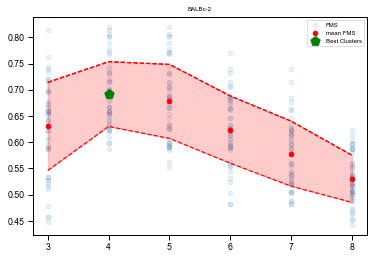

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [03:17<00:00, 24.72s/it]


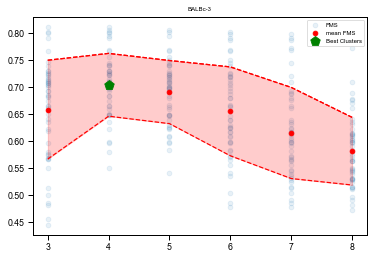

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [03:33<00:00, 26.68s/it]


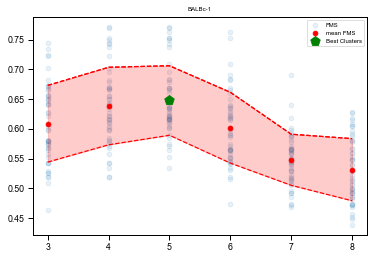

In [206]:
balbc_samples = set(balbc_samples_df_all['sample'])

sample_to_ccs_result_mm = {}

for sample in balbc_samples:
    sample_to_ccs_result_mm[sample] = ccs.cellohood_cluster_selection(
        x=agg_markers[mean_marker_samples == sample],
        clusters_to_analyze=list(range(2, 10)),
        #take_every_example_for_training=10,
    )
    ccs.plot_ccs_result(sample_to_ccs_result_mm[sample])
    plt.title(sample)
    plt.show()

In [207]:
sample_to_predictions_mm = {}

for sample in balbc_samples:
    best_clusterer_ind = 4 if 4 in sample_to_ccs_result_mm[sample].best_clusterers else 5
    raw_cc = balbc_samples_df_all[balbc_samples_df_all['sample'] == sample]['cellohood_neighborhood_cluster']
    raw_cc = raw_cc - raw_cc.iloc[0]
    raw_predictions = sample_to_ccs_result_mm[sample].best_clusterers[
        best_clusterer_ind
    ].predict(agg_markers[mean_marker_samples == sample])
    sample_to_predictions_mm[sample] = numpy.array([raw_predictions[i] for i in raw_cc])

In [208]:
sample_amis_mm, sample_f1s_mm = [], []


for sample in set(balbc_samples_df['sample']):
    best_clusterer_ind = 4 if 4 in sample_to_ccs_result_mm[sample].best_clusterers else 5
    print(sample)
    sample_df = balbc_samples_df[balbc_samples_df['sample'] == sample]
    classes = sample_to_predictions_mm[sample]

    classes_dict = {
        cl: sample_df['CompartmentValidInt'][classes == cl].mode().values[0]
        for cl in range(best_clusterer_ind)
    }
    
    corrected_classes = numpy.array([classes_dict[x] for x in classes])
    sample_to_predictions[sample] = corrected_classes
    
    sample_amis_mm.append(
        ami(
            sample_df['Compartment'][sample_df['CompartmentValidInt'].isin(list(range(4)))], 
            classes[sample_df['CompartmentValidInt'].isin(list(range(4)))]
        )
    )
    sample_f1s_mm.append(f1_score(
        sample_df['CompartmentValidInt'][sample_df['CompartmentValidInt'].isin(list(range(4)))], 
        corrected_classes[sample_df['CompartmentValidInt'].isin(list(range(4))).values],
        average='macro',
    ))

BALBc-2
BALBc-3
BALBc-1


In [209]:
sample_amis_mm, sample_f1s_mm

([0.40980945165833116, 0.38590163512912984, 0.35649674039353835],
 [0.5836534614969006, 0.5477957550590425, 0.5512632329366298])

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [03:51<00:00, 28.90s/it]


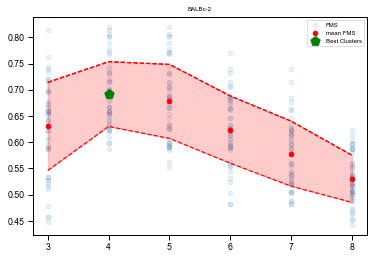

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [03:17<00:00, 24.68s/it]


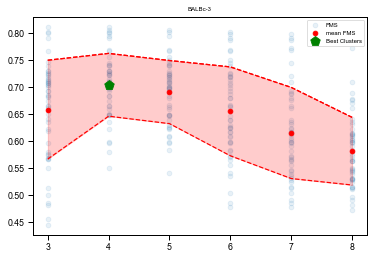

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [03:32<00:00, 26.61s/it]


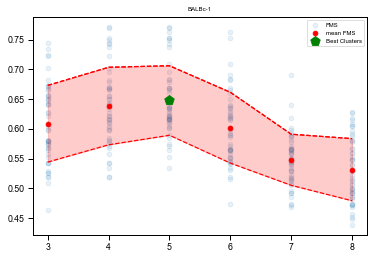

In [210]:
balbc_samples = set(balbc_samples_df_all['sample'])

sample_to_ccs_result_mm = {}

for sample in balbc_samples:
    sample_to_ccs_result_mm[sample] = ccs.cellohood_cluster_selection(
        x=agg_markers[mean_marker_samples == sample],
        clusters_to_analyze=list(range(2, 10)),
        #take_every_example_for_training=10,
    )
    ccs.plot_ccs_result(sample_to_ccs_result_mm[sample])
    plt.title(sample)
    plt.show()

In [1073]:
f1_scores['Agg.CBR'] = sample_f1s_mm
ami_scores['Agg.CBR'] = sample_amis_mm

In [1074]:
ALTERNATIVE = 'greater'

f1s_p_vals = numpy.zeros((len(f1s_df.columns), len(f1s_df.columns)))
amis_p_vals = numpy.zeros((len(f1s_df.columns), len(f1s_df.columns)))

for l_ind, l_col in enumerate(f1s_df.columns):
    for r_ind, r_col in enumerate(f1s_df.columns):
        f1s_p_vals[l_ind, r_ind] = ttest_ind(f1s_df[l_col], f1s_df[r_col], alternative=ALTERNATIVE).pvalue
        amis_p_vals[l_ind, r_ind] = ttest_ind(amis_df[l_col], amis_df[r_col], alternative=ALTERNATIVE).pvalue

## Latent Representations

In [213]:
balbc_samples_df_all[DUMMY_COL_NAME] = 1

/tmp/ipykernel_2946542/1128866026.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  balbc_samples_df_all[DUMMY_COL_NAME] = 1


In [214]:
celltype_histogram = pandas.pivot_table(
    balbc_samples_df_all,
    values=DUMMY_COL_NAME,
    columns='celltype',
    index='cellohood_neighborhood_cluster',
    aggfunc='sum',
).fillna(0)

celltype_histogram = (celltype_histogram.T / celltype_histogram.T.sum(axis=0)).T

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [03:13<00:00, 24.23s/it]


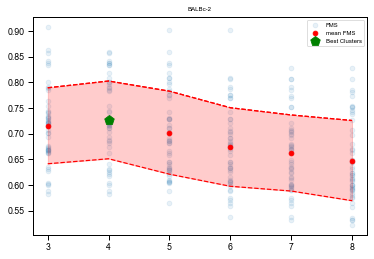

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [03:33<00:00, 26.70s/it]


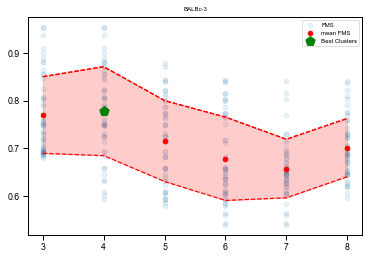

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [03:13<00:00, 24.16s/it]


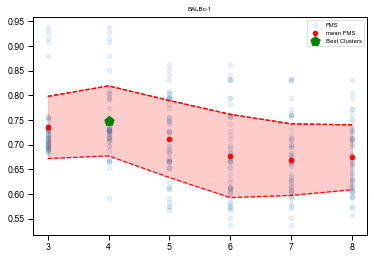

In [215]:
balbc_samples = set(balbc_samples_df_all['sample'])

sample_to_ccs_result_cth = {}

for sample in balbc_samples:
    sample_to_ccs_result_cth[sample] = ccs.cellohood_cluster_selection(
        x=celltype_histogram[mean_marker_samples == sample],
        clusters_to_analyze=list(range(2, 10)),
        #take_every_example_for_training=10,
    )
    ccs.plot_ccs_result(sample_to_ccs_result_cth[sample])
    plt.title(sample)
    plt.show()

In [1033]:
sample_to_predictions_cth = {}
sample_to_corrected_predictions_cth = {}

for sample in balbc_samples:
    best_clusterer_ind = 4 #if 4 in sample_to_ccs_result_mm[sample].best_clusterers else 5
    raw_cc = balbc_samples_df_all[balbc_samples_df_all['sample'] == sample]['cellohood_neighborhood_cluster']
    raw_cc = raw_cc - raw_cc.iloc[0]
    raw_predictions = sample_to_ccs_result_cth[sample].best_clusterers[
        best_clusterer_ind
    ].predict(celltype_histogram[mean_marker_samples == sample])
    sample_to_predictions_cth[sample] = numpy.array([raw_predictions[i] for i in raw_cc])

In [1034]:
sample_amis_cth, sample_f1s_cth = [], []


for sample in set(balbc_samples_df['sample']):
    best_clusterer_ind = 4# if 4 in sample_to_ccs_result_mm[sample].best_clusterers else 5
    print(sample)
    sample_df = balbc_samples_df[balbc_samples_df['sample'] == sample]
    classes = sample_to_predictions_cth[sample]

    classes_dict = {
        cl: sample_df['CompartmentValidInt'][classes == cl].mode().values[0]
        for cl in range(best_clusterer_ind)
    }
    
    corrected_classes = numpy.array([classes_dict[x] for x in classes])
    sample_to_corrected_predictions_cth[sample] = corrected_classes
    
    sample_amis_cth.append(
        ami(
            sample_df['Compartment'][sample_df['CompartmentValidInt'].isin(list(range(4)))], 
            classes[sample_df['CompartmentValidInt'].isin(list(range(4)))]
        )
    )
    sample_f1s_cth.append(f1_score(
        sample_df['CompartmentValidInt'][sample_df['CompartmentValidInt'].isin(list(range(4)))], 
        corrected_classes[sample_df['CompartmentValidInt'].isin(list(range(4))).values],
        average='macro',
    ))

BALBc-2
BALBc-3
BALBc-1


In [1075]:
f1_scores['CTH.CBR'] = sample_f1s_cth
ami_scores['CTH.CBR'] = sample_amis_cth

In [1122]:
method_cmap = plt.get_cmap('tab20', 7)

f1s_df = pandas.DataFrame(f1_scores)
amis_df = pandas.DataFrame(ami_scores)

def AnnoMe2(x1, x2, y, txt, h=0.005, offset=0, col='gray', fontsize=5, lw=0.5):
    plt.plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=lw, c=col)
    plt.text((x1+x2)*.5, y+h - offset, '   ' + txt, ha='center', va='bottom', c=col, fontsize=fontsize)
    
    
def get_stars_from_pval(pval):
    pval_adj = f''
    if pval >= 0.01:
        pval_adj += f'={round(pval, 2)}'
    elif pval >= 0.001:
        pval_adj += f'={round(pval, 3)}'
    else:
        pval_adj += '<0.001'
    result = f'p{pval_adj} ('
    if pval < 0.05:
        result += '*'
    if pval < 0.01:
        result += '*'
    if pval < 0.001:
        result += '*'
    if pval >= 0.05:
        result += 'ns'
    return result + ')'

In [1123]:
ALTERNATIVE = 'greater'

f1s_p_vals = numpy.zeros((len(f1s_df.columns), len(f1s_df.columns)))
amis_p_vals = numpy.zeros((len(amis_df.columns), len(amis_df.columns)))

for l_ind, l_col in enumerate(amis_df.columns):
    for r_ind, r_col in enumerate(amis_df.columns):
        f1s_p_vals[l_ind, r_ind] = ttest_ind(f1s_df[l_col], f1s_df[r_col], alternative=ALTERNATIVE).pvalue
        amis_p_vals[l_ind, r_ind] = ttest_ind(
            amis_df[l_col], 
            amis_df[r_col],
            alternative=ALTERNATIVE,
            equal_var=False,
        ).pvalue

In [1130]:
amis_df.columns = [col.replace('CTH.CTH', 'CTH.CBR') for col in amis_df.columns]
f1s_df.columns = [col.replace('CTH.CTH', 'CTH.CBR') for col in f1s_df.columns]

In [1131]:
ext_method_cmap = plt.get_cmap('tab20', 9)

/tmp/ipykernel_2946542/295228820.py:5: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter([ind_] * 3, f1s_df[col], c=ext_method_cmap(ind_), s=20, alpha=0.4)
/tmp/ipykernel_2946542/295228820.py:6: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter([ind_], [f1s_df[col].mean()], marker='_', c=ext_method_cmap(ind_), s=50)
/tmp/ipykernel_2946542/295228820.py:31: UserWarning: *c* argument looks like a single numeric 

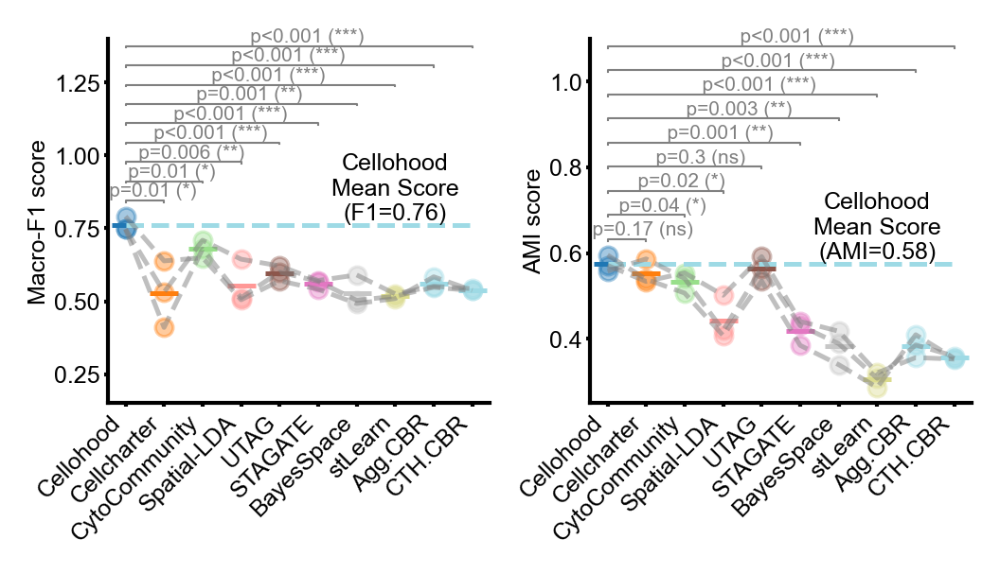

In [1132]:
plt.figure(figsize=(3.5, 2), dpi=300)

plt.subplot(1, 2, 1)
for ind_, col in enumerate(f1s_df.columns):
    plt.scatter([ind_] * 3, f1s_df[col], c=ext_method_cmap(ind_), s=20, alpha=0.4)
    plt.scatter([ind_], [f1s_df[col].mean()], marker='_', c=ext_method_cmap(ind_), s=50)
    
    
plt.plot([0, 9], [f1s_df['Cellohood'].mean()] * 2, linestyle='dashed', c=method_cmap(ind_))
plt.text(7, f1s_df['Cellohood'].mean(), f'Cellohood\nMean Score\n(F1={round(f1s_df["Cellohood"].mean(), 2)})', ha='center', va='bottom')

for other, x in enumerate(numpy.linspace(0.82, 1.35, len(f1s_p_vals) - 1)):
    AnnoMe2(0, other + 1, x + 0.02, get_stars_from_pval(f1s_p_vals[0, other + 1]))
    
plt.ylim([0.15, 1.4])
plt.plot(f1s_df.loc[0], c='gray', linestyle='dashed', alpha=0.5)
plt.plot(f1s_df.loc[1], c='gray', linestyle='dashed', alpha=0.5)
plt.plot(f1s_df.loc[2], c='gray', linestyle='dashed', alpha=0.5)
plt.xticks(rotation=45, size=6, ha='right')
plt.yticks(size=6)
plt.ylabel('Macro-F1 score', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'right']].set_visible(False)
ax.yaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)


plt.subplot(1, 2, 2)

for ind_, col in enumerate(amis_df.columns):
    plt.scatter([ind_] * 3, amis_df[col], c=ext_method_cmap(ind_), s=20, alpha=0.4)
    plt.scatter([ind_], [amis_df[col].mean()], marker='_', c=ext_method_cmap(ind_), s=50)
    
plt.plot([0, 9], [amis_df['Cellohood'].mean()] * 2, linestyle='dashed', c=ext_method_cmap(ind_))
plt.text(7, amis_df['Cellohood'].mean(), f'Cellohood\nMean Score\n(AMI={round(amis_df["Cellohood"].mean(), 2)})', ha='center', va='bottom')
plt.ylim([0, 1])
    
for other, x in enumerate(numpy.linspace(0.6, 1.05, 9)):
    AnnoMe2(0, other + 1, x + 0.028, '   ' + get_stars_from_pval(amis_p_vals[0, other + 1]))
    
plt.ylim([0.25, 1.1])
plt.plot(amis_df.loc[0], c='gray', linestyle='dashed', alpha=0.5)
plt.plot(amis_df.loc[1], c='gray', linestyle='dashed', alpha=0.5)
plt.plot(amis_df.loc[2], c='gray', linestyle='dashed', alpha=0.5)
plt.xticks(rotation=45, size=6, ha='right')
plt.yticks(size=6)
plt.ylabel('AMI score', size=6, labelpad=1)
ax = plt.gca()
ax.spines[['top', 'right']].set_visible(False)
ax.yaxis.set_tick_params(size=1, pad=1)
ax.xaxis.set_tick_params(size=1, pad=1)

plt.tight_layout()

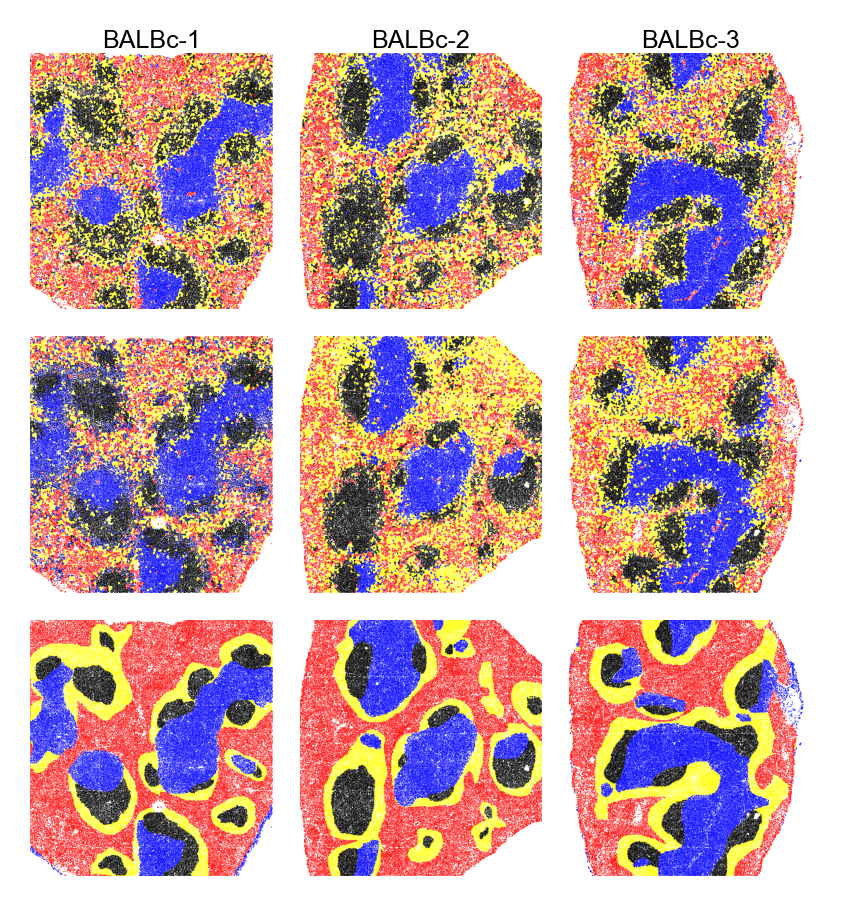

In [1133]:
plt.figure(figsize=(6.5 / 7 * 3, 3), dpi=300)

plt.subplot(3, 3, 1)

balbc1_preds_cth = sample_to_predictions_cth['BALBc-1'][
    balbc1_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=[agg_cth_colors_cc_b1[x] for x in balbc1_preds_cth],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])
plt.title('BALBc-1', size=6, pad=1)
plt.ylabel('AGG.CTH')


plt.subplot(3, 3, 2)

balbc2_preds_cth = sample_to_predictions_cth['BALBc-2'][
    balbc2_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=[agg_cth_colors_cc_b2[x] for x in balbc2_preds_cth],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])
plt.title('BALBc-2', size=6, pad=1)


plt.subplot(3, 3, 3)

balbc3_preds_cth = sample_to_predictions_cth['BALBc-3'][
    balbc3_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=[agg_cth_colors_cc_b3[x] for x in balbc3_preds_cth],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])

plt.title('BALBc-3', size=6, pad=1)

plt.subplot(3, 3, 4)

balbc1_preds_mm = sample_to_predictions_mm['BALBc-1'][
    balbc1_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=[agg_cth_colors_mm_b1[x] for x in balbc1_preds_mm],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])
plt.ylabel('AGG.CBR')

plt.subplot(3, 3, 5)

balbc2_preds_mm = sample_to_predictions_mm['BALBc-2'][
    balbc2_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=[agg_cth_colors_mm_b2[x] for x in balbc2_preds_mm],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])


plt.subplot(3, 3, 6)

balbc3_preds_mm = sample_to_predictions_mm['BALBc-3'][
    balbc3_all_df['Compartment'].apply(lambda x: x in compartments[:4])
]

plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=[agg_cth_colors_mm_b3[x] for x in balbc3_preds_mm],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])


plt.subplot(3, 3, 7)

plt.scatter(
    x=balbc1_df['tile.X'],
    y=balbc1_df['tile.Y'],
    c=[colors_cc(x) for x in balbc1_df['CompartmentValidInt']],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])
plt.ylabel('Ground truth')


plt.subplot(3, 3, 8)

plt.scatter(
    x=balbc2_df['tile.X'],
    y=balbc2_df['tile.Y'],
    c=[colors_cc(x) for x in balbc2_df['CompartmentValidInt']],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])


plt.subplot(3, 3, 9)

plt.scatter(
    x=balbc3_df['tile.X'],
    y=balbc3_df['tile.Y'],
    c=[colors_cc(x) for x in balbc3_df['CompartmentValidInt']],
    s=0.01,
    linewidths=0.2,
    alpha=SCATTER_ALPHA,
)
plt.axis('off')
ax = plt.gca()
ax.spines[['top', 'left']].set_visible(False)
ax.spines[['bottom', 'right']].set_visible(False)
_ = ax.set_xticks([])
_ = ax.set_yticks([])
ax.set_aspect('auto')
ax.set_xlim([sample_df['tile.X'].min(), sample_df['tile.X'].max()])
ax.set_ylim([sample_df['tile.Y'].min(), sample_df['tile.Y'].max()])

plt.tight_layout()

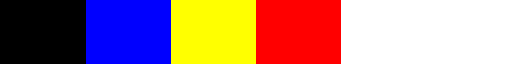

In [1127]:
agg_cth_colors_cc_b1 = {
    0: mcolors.CSS4_COLORS['yellow'],
    1: mcolors.CSS4_COLORS['blue'],
    2: mcolors.CSS4_COLORS['black'],
    3: mcolors.CSS4_COLORS['red'],
}


agg_cth_colors_cc_b2 = {
    0: mcolors.CSS4_COLORS['yellow'],
    1: mcolors.CSS4_COLORS['black'],
    2: mcolors.CSS4_COLORS['red'],
    3: mcolors.CSS4_COLORS['blue'],
}

agg_cth_colors_cc_b3 = {
    0: mcolors.CSS4_COLORS['blue'],
    1: mcolors.CSS4_COLORS['black'],
    2: mcolors.CSS4_COLORS['yellow'],
    3: mcolors.CSS4_COLORS['red'],
}

agg_cth_colors_mm_b1 = {
    0: mcolors.CSS4_COLORS['yellow'],
    1: mcolors.CSS4_COLORS['red'],
    2: mcolors.CSS4_COLORS['darkblue'],
    3: mcolors.CSS4_COLORS['black'],
    4: mcolors.CSS4_COLORS['blue'],
}


agg_cth_colors_mm_b2 = {
    0: mcolors.CSS4_COLORS['blue'],
    1: mcolors.CSS4_COLORS['black'],
    2: mcolors.CSS4_COLORS['yellow'],
    3: mcolors.CSS4_COLORS['red'],
}


agg_cth_colors_mm_b3 = {
    0: mcolors.CSS4_COLORS['red'],
    1: mcolors.CSS4_COLORS['blue'],
    2: mcolors.CSS4_COLORS['yellow'],
    3: mcolors.CSS4_COLORS['black'],
}

colors_cc